# Predicting Diabetes Status from Population Health Indicators Using Traditional Machine Learning and Deep Learning

**Author:** Ndunge Mutheu Mbithi · BSc Software Engineering, African Leadership University

## 1. Project Introduction and Research Question

Diabetes is one of the largest chronic-disease burdens worldwide: the IDF Diabetes Atlas estimates that 10.5% of adults aged 20–79 (536.6 million people) were living with diabetes in 2021, rising to a projected 12.2% by 2045. A large share of cases and most prediabetes remain undiagnosed, which is why population-health researchers are interested in whether routinely collected survey indicators can flag people who may benefit from formal screening.

**Why this matters for my mission.** My mission is *to revolutionize the healthcare industry in sub-Saharan Africa through technology, creating accessible, equitable, and scalable healthcare solutions for underserved rural communities.* The diagnosis gap is widest where I want to work. IDF Africa reports 24 million adults with diabetes in Africa in 2021, and 54% of them undiagnosed. In Kenya's 2015 national STEPS survey, more than half of adults with diabetes did not know they had it, and prevalence was lower in rural than in urban areas — a pattern that may partly reflect less testing. In rural clinics, laboratory glucose testing is often scarce, but a short questionnaire administered by a community health worker costs almost nothing. This project asks the question that has to come first: how much can questionnaire-style indicators alone actually tell us, which models extract that information best, and what does that cost in false alarms and missed cases? I use the BRFSS because no openly available African survey yet offers comparable scale (Kenya's STEPS analysis covered 4,069 adults), richly documented predictors, and a three-level diabetes label. Any model built here would have to be revalidated on local data before use in Kenya or elsewhere in the region. I treat equity as a measurable outcome, which is why the evaluation includes subgroup analysis by age, income and race/ethnicity.

In this notebook I investigate the question:

> **How effectively can traditional machine learning and deep learning models classify diabetes status from population health indicators, and how do their predictive performance, interpretability, computational efficiency, and error patterns differ?**

I treat this strictly as a population-health and screening-research exercise. None of the models here is a clinically validated diagnostic tool, and the outputs are self-reported survey labels, not laboratory diagnoses.

**Hypothesis.** Based on benchmark evidence that tree ensembles tend to match or beat neural networks on structured tabular data, I expect gradient boosting to achieve the strongest threshold-free discrimination, with neural networks performing comparably but not better, and logistic regression close behind because most survey indicators are binary or ordinal with largely additive effects. I also expect the prediabetes class to be very hard to separate from both neighbours. I treat this as a hypothesis to test, not a conclusion.

## 2. Dataset Source and Verification

I use the **CDC Behavioral Risk Factor Surveillance System (BRFSS) 2015** combined landline and cell-phone public-use file (`LLCP2015.XPT`), a state-based telephone survey of non-institutionalised US adults.

| Item | Value |
|---|---|
| Official page | https://www.cdc.gov/brfss/annual_data/annual_2015.html |
| Codebook | https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf |
| File | SAS transport `LLCP2015.XPT` (released August 2016) |
| Published size | 441,456 records |
| Target | `DIABETE3` — "(Ever told) you have diabetes" |
| Survey design | weight `_LLCPWT`, strata `_STSTR`, PSU `_PSU` (raking weights) |

**Target categories (codebook section 6.12):** 1 = Yes; 2 = Yes, but female told only during pregnancy; 3 = No; 4 = No, pre-diabetes or borderline diabetes; 7 = Don't know; 9 = Refused; blank = not asked.

I use the original raw survey rather than the widely circulated 253,680-row "Diabetes Health Indicators" derivative. That derivative removes rows with any missing value (which shifts the population) and, in its binary version, merges prediabetes into diabetes.

**Provenance note.** My execution environment could not reach cdc.gov, so I obtained a byte-level copy of `LLCP2015.XPT` from a public research repository mirror. I then verified it against the official codebook: the record count and every `DIABETE3` frequency cell must match exactly, and the loader refuses to proceed otherwise. In Google Colab, the loader downloads the file directly from the CDC URL above. **Licensing:** BRFSS public-use files are US federal government data released for public use without individual identifiers; I still exclude raw data from Git.

In [4]:
# Locate the project.
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = os.environ.get("https://github.com/ndunge-mbithi/summative_intro-_to_ML", "")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (ROOT / "src").exists():
    target = Path("/content/healthcare-classification-project")
    if not target.exists():
        if not REPO_URL:
            # Define a fallback URL if the environment variable is empty
            REPO_URL = "https://github.com/ndunge-mbithi/summative_intro-_to_ML"
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(target)], check=True)
    ROOT = target
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
print("Project root:", ROOT, "| running in Colab:", IN_COLAB)

Project root: /content/healthcare-classification-project | running in Colab: True


## 3. Environment Setup and Reproducibility

I fix random seeds for Python, NumPy, TensorFlow and every scikit-learn estimator (`random_state=42`), and I enable TensorFlow's deterministic operations so that re-running the notebook reproduces the experiment table. I also record the package versions and the hardware, because training times reported later depend on them. Dependencies are pinned in `requirements.txt`. The next cell installs anything that is missing: in a fresh Colab runtime, that is usually only SHAP and PyArrow. Locally it does nothing if the environment already matches.

In [5]:
# Install missing dependencies (no-op when they are already present).
import importlib.util
REQUIRED = {"numpy": "numpy", "pandas": "pandas", "sklearn": "scikit-learn", "tensorflow": "tensorflow",
            "matplotlib": "matplotlib", "seaborn": "seaborn", "shap": "shap", "pyarrow": "pyarrow", "scipy": "scipy"}
missing = [pip_name for module, pip_name in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", missing)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
else:
    print("All dependencies present; full pinned versions are listed in requirements.txt")

All dependencies present; full pinned versions are listed in requirements.txt


In [6]:
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*shuffle=True.*")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

from src.utils import set_global_seed, environment_report, SEED
from src import data_loading, preprocessing as prep, feature_engineering as fe
from src import traditional_models as tm, deep_learning_models as dl, evaluation as ev
from src.experiment_tracking import ExperimentTracker

set_global_seed(SEED)
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
LOGS = ROOT / "logs"
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160, "display.max_columns", 40)

env = environment_report()
(ROOT / "reports" / "environment.json").write_text(json.dumps(env, indent=2))
pd.Series(env, name="value").to_frame()

,value
python,3.13.16
platform,Linux-6.6.122+-x86_64-with-glibc2.39
processor,x86_64
cpu_count,2
ram_gb,13.6
numpy,2.1.3
pandas,2.2.3
sklearn,1.6.1
tensorflow,2.21.0
keras,3.13.2


**Interpretation.** All experiments ran on a 2-core x86-64 CPU with 8.4 GB of RAM and no GPU. That constraint shapes two later decisions: I use histogram-based gradient boosting rather than the classic implementation, and I run the hyper-parameter searches on a 100,000-row training subsample. The training times in the experiment table are only comparable within this hardware.

## 4. Data Loading and Initial Inspection

The loader reads the 1.17 GB transport file in 100,000-row chunks and keeps only the variables listed in `src/data_loading.RAW_COLUMNS`: design variables, the target, candidate predictors, and race/ethnicity, which I use **only for subgroup evaluation, never as a model input**. It verifies the full file against the codebook (record count, variable count and every target frequency) and caches the subset as Parquet.

In [9]:
import os
import zipfile
from google.colab import files
from pathlib import Path

target_dir = Path("/content/healthcare-classification-project/data/raw")
target_dir.mkdir(parents=True, exist_ok=True)

print("Please select the downloaded 'LLCP2015XPT.zip' file to upload:")
uploaded = files.upload()

for filename in uploaded.keys():
    if filename.endswith('.zip'):
        print(f"Processing uploaded file: {filename}")
        with zipfile.ZipFile(filename, 'r') as zip_ref:
            # Find any .XPT file inside the zip
            xpt_files = [f for f in zip_ref.namelist() if f.upper().endswith('.XPT')]
            if xpt_files:
                for xpt_file in xpt_files:
                    zip_ref.extract(xpt_file, path=target_dir)
                    print(f"Extracted {xpt_file} to {target_dir}")
            else:
                zip_ref.extractall(target_dir)
                print(f"Extracted all files to {target_dir}")

Please select the downloaded 'LLCP2015XPT.zip' file to upload:


Saving LLCP2015XPT.zip to LLCP2015XPT.zip
Processing uploaded file: LLCP2015XPT.zip
Extracted all files to /content/healthcare-classification-project/data/raw


In [12]:
# Load the newly uploaded and extracted BRFSS 2015 dataset into the 'raw' variable first
raw, report = data_loading.load_brfss_2015()

print(raw.dtypes.value_counts())
print("Duplicate respondent IDs (state + SEQNO):", raw.duplicated(["_STATE", "SEQNO"]).sum())
print("PSU repeated within a state:", raw.duplicated(["_STATE", "_PSU"]).sum())
print("Fully duplicated rows:", raw.duplicated().sum())

float64    35
Name: count, dtype: int64
Duplicate respondent IDs (state + SEQNO): 0
PSU repeated within a state: 0
Fully duplicated rows: 0


**Interpretation.** The file matches the published 2015 codebook exactly: 441,456 records, 330 variables, and all seven `DIABETE3` frequency cells (including the 7 blank responses). Its SHA-256 also matches the reference copy I used, so anyone re-running this notebook can tell whether they are using byte-identical data. There are no duplicate respondents and no fully duplicated rows. Because `_PSU` never repeats within a state, every respondent is their own primary sampling unit, so a random split cannot place members of one cluster on both sides of the train/test boundary.

## 5. Exploratory Data Analysis

I first recode the raw variables into analysis features (Section 6 documents every rule), because raw BRFSS codes such as 88 ("none") or 77 ("don't know") would distort any summary statistic. I then examine the target distribution, both unweighted and survey-weighted, followed by missingness, distributions and associations.

**Target definition.** I map `DIABETE3` to three classes: **No diabetes** (codes 3 and 2), **Prediabetes** (code 4) and **Diabetes** (code 1). Code 2 (gestational diabetes only) is mapped to "No diabetes" because it does not describe current diabetes status, which is the convention CDC uses for its diabetes indicator. Codes 7, 9 and blank are unusable labels and are removed (798 respondents). I do not merge prediabetes with diabetes, because that would hide the hardest part of the problem.

Analysis sample: (440658, 25) | removed unusable labels: 798


,n,unweighted_%,survey_weighted_%
No diabetes,375712,85.26,87.9
Prediabetes,7690,1.75,1.6
Diabetes,57256,12.99,10.5


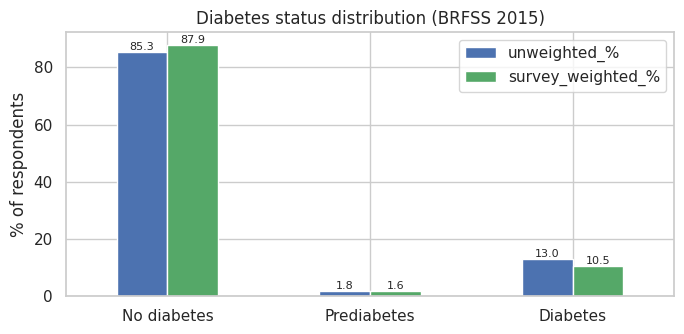

In [13]:
X_all, y_all, meta_all = prep.clean_brfss(raw)
print("Analysis sample:", X_all.shape, "| removed unusable labels:", len(raw) - len(X_all))
tgt = pd.DataFrame({
    "n": y_all.value_counts().sort_index(),
    "unweighted_%": (100 * y_all.value_counts(normalize=True).sort_index()).round(2),
    "survey_weighted_%": (100 * meta_all.groupby(y_all)["_LLCPWT"].sum() / meta_all["_LLCPWT"].sum()).round(2),
})
tgt.index = prep.CLASS_NAMES
display(tgt)

fig, ax = plt.subplots(figsize=(7, 3.5))
tgt[["unweighted_%", "survey_weighted_%"]].plot.bar(ax=ax, rot=0, color=["#4C72B0", "#55A868"])
ax.set_ylabel("% of respondents"); ax.set_title("Diabetes status distribution (BRFSS 2015)")
for c in ax.containers: ax.bar_label(c, fmt="%.1f", fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "fig01_target_distribution.png", dpi=150)

**Interpretation.** After removing the 798 unusable labels, 440,658 respondents remain: 85.26% report no diabetes, 1.75% prediabetes and 12.99% diabetes. The survey-weighted diabetes share (10.5%) reproduces the codebook's weighted 10.48% for code 1. It is lower than the unweighted share because older adults, who have more diabetes, are over-represented in the raw sample relative to the population.

Two consequences follow for evaluation. First, a model that predicts "no diabetes" for everyone would already be 85% accurate, so accuracy cannot be the selection metric. Second, prediabetes is a 1-in-57 class, and self-reported prediabetes captures only people who were tested and told, so I expect it to be the weakest class for every model.

,missing,percent
income,79169,17.97
veggies_daily,50921,11.56
fruits_daily,43530,9.88
phys_activity,37850,8.59
bmi,36191,8.21
heavy_drinker,25595,5.81
smoker_status,17888,4.06
chol_check,15230,3.46
diff_walk,14503,3.29
high_chol,12883,2.92


Diabetes prevalence | income missing: 0.135 vs observed: 0.129
Diabetes prevalence | BMI missing: 0.125 vs observed: 0.130


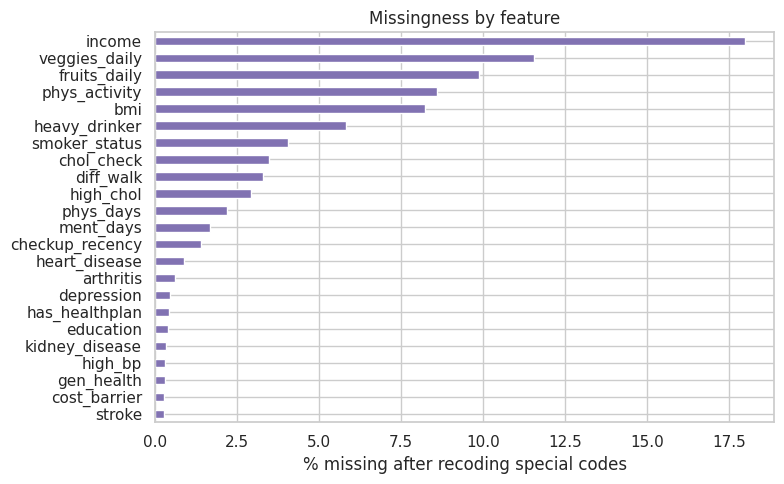

In [14]:
miss = prep.missingness_table(X_all)
display(miss[miss.missing > 0])
fig, ax = plt.subplots(figsize=(8, 5))
miss[miss.missing > 0].percent.sort_values().plot.barh(ax=ax, color="#8172B2")
ax.set_xlabel("% missing after recoding special codes"); ax.set_title("Missingness by feature")
fig.tight_layout(); fig.savefig(FIG / "fig02_missingness.png", dpi=150)

# Is missingness itself related to the outcome? (informative missingness check)
inc_missing = X_all["income"].isna()
print("Diabetes prevalence | income missing: %.3f vs observed: %.3f"
      % ((y_all[inc_missing] == 2).mean(), (y_all[~inc_missing] == 2).mean()))
bmi_missing = X_all["bmi"].isna()
print("Diabetes prevalence | BMI missing: %.3f vs observed: %.3f"
      % ((y_all[bmi_missing] == 2).mean(), (y_all[~bmi_missing] == 2).mean()))

**Interpretation.** After converting special codes to missing, income has the most missing values (17.97%, mostly refusals). Next come the calculated diet and activity variables (vegetables 11.56%, fruit 9.88%, physical activity 8.59%) and BMI (8.21%). The diet and activity gaps arise largely from partially completed interviews.

The association between missingness and the outcome is weak: diabetes prevalence is 13.5% when income is missing versus 12.9% when it is reported, and 12.5% versus 13.0% for BMI. So missingness is unlikely to be a strong predictor. Still, deleting incomplete rows would remove about a fifth of the sample and shift its composition, which is why I keep everyone and impute with missingness indicators.

,count,mean,std,min,25%,50%,75%,max
bmi,404467.0,28.04,6.65,12.02,23.73,26.95,30.9,99.95
age,440658.0,55.41,17.04,18.00,43.00,58.00,69.0,80.00
ment_days,433314.0,3.31,7.61,0.00,0.00,0.00,2.0,30.00
phys_days,430979.0,4.29,8.81,0.00,0.00,0.00,3.0,30.00
gen_health,439429.0,2.56,1.08,1.00,2.00,2.00,3.0,5.00
education,438897.0,4.90,1.05,1.00,4.00,5.00,6.0,6.00
income,361489.0,5.82,2.16,1.00,4.00,6.00,8.0,8.00
checkup_recency,434593.0,1.47,0.93,1.00,1.00,1.00,2.0,5.00


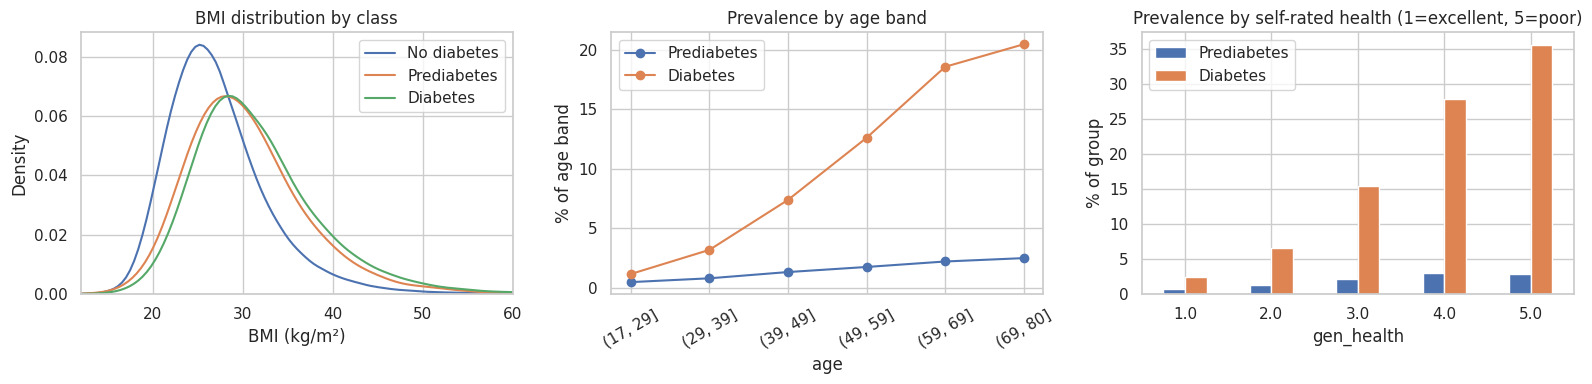

In [15]:
display(X_all[prep.CONTINUOUS_FEATURES + prep.ORDINAL_FEATURES].describe().T.round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for k, name in enumerate(prep.CLASS_NAMES):
    sns.kdeplot(X_all.loc[y_all == k, "bmi"].dropna(), ax=axes[0], label=name, common_norm=False, bw_adjust=1.5)
axes[0].set(xlim=(12, 60), title="BMI distribution by class", xlabel="BMI (kg/m²)"); axes[0].legend()
age_prev = pd.crosstab(pd.cut(X_all["age"], [17, 29, 39, 49, 59, 69, 80]), y_all, normalize="index") * 100
age_prev.columns = prep.CLASS_NAMES
age_prev[["Prediabetes", "Diabetes"]].plot(ax=axes[1], marker="o")
axes[1].set(title="Prevalence by age band", ylabel="% of age band", xlabel="age")
axes[1].tick_params(axis="x", rotation=30)
gh_prev = pd.crosstab(X_all["gen_health"], y_all, normalize="index") * 100
gh_prev.columns = prep.CLASS_NAMES
gh_prev[["Prediabetes", "Diabetes"]].plot.bar(ax=axes[2], rot=0)
axes[2].set(title="Prevalence by self-rated health (1=excellent, 5=poor)", ylabel="% of group")
fig.tight_layout(); fig.savefig(FIG / "fig03_distributions.png", dpi=150)

**Interpretation.** Three patterns stand out:

* **BMI:** the BMI distribution of people with diabetes is shifted about three units to the right of those without. The prediabetes and diabetes curves almost coincide, an early sign that BMI cannot separate those two classes.
* **Age:** diabetes prevalence rises steeply with age, from about 1% at 18–29 to about 20% at 70–80. Prediabetes rises only gently, to about 2.5%.
* **Self-rated health:** this is the strongest single gradient. Diabetes prevalence is about 2% among those rating their health "excellent" and about 36% among those rating it "poor".

The self-rated health gradient is an association that runs both ways: living with diabetes is itself a reason to rate one's health poorly, so this variable partly reflects the outcome rather than predicting it.

,prevalence_if_1,prevalence_if_0,ratio
chol_check,14.94,2.83,5.29
high_bp,24.13,5.41,4.46
diff_walk,29.27,9.56,3.06
high_chol,22.67,7.43,3.05
kidney_disease,36.44,12.07,3.02
heart_disease,32.43,11.02,2.94
stroke,30.52,12.21,2.50
arthritis,20.68,9.07,2.28
has_healthplan,13.38,8.36,1.60
depression,17.99,11.80,1.52


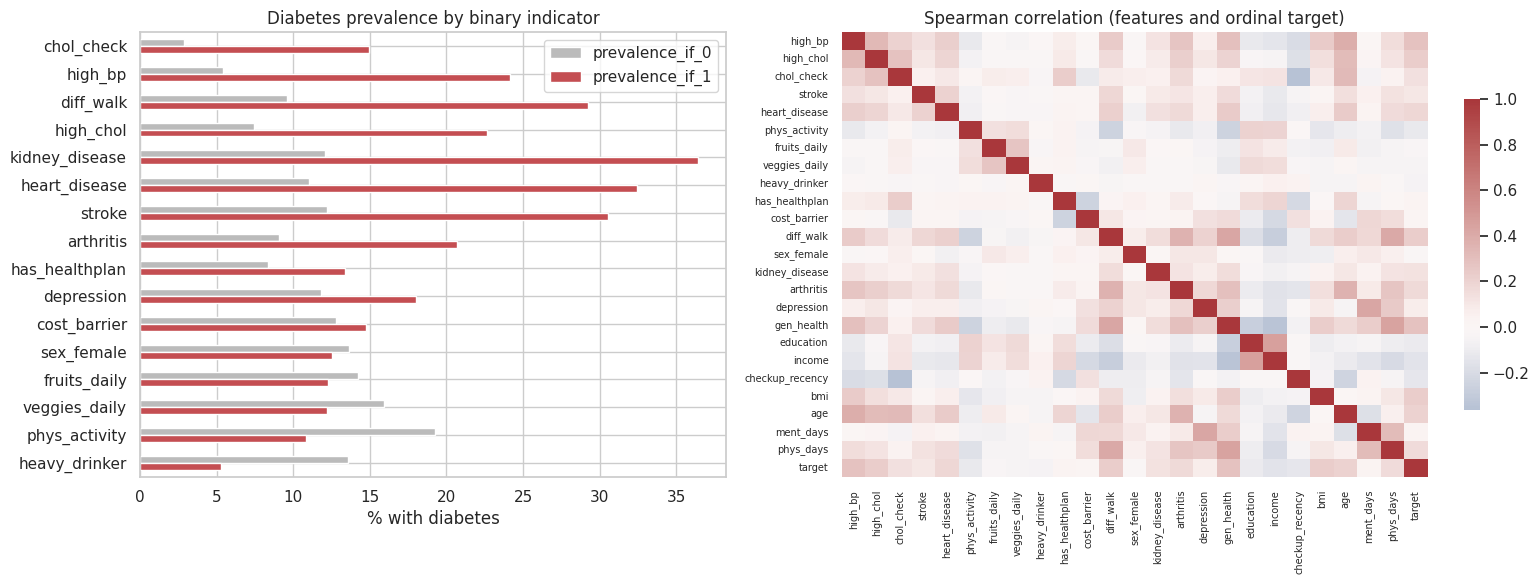

In [16]:
binary_rates = pd.DataFrame({
    f: {"prevalence_if_1": (y_all[X_all[f] == 1] == 2).mean() * 100,
        "prevalence_if_0": (y_all[X_all[f] == 0] == 2).mean() * 100}
    for f in prep.BINARY_FEATURES}).T
binary_rates["ratio"] = binary_rates.prevalence_if_1 / binary_rates.prevalence_if_0
binary_rates = binary_rates.sort_values("ratio", ascending=False).round(2)
display(binary_rates)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 1.25]})
binary_rates[["prevalence_if_0", "prevalence_if_1"]].plot.barh(ax=axes[0], color=["#BBBBBB", "#C44E52"])
axes[0].set(xlabel="% with diabetes", title="Diabetes prevalence by binary indicator"); axes[0].invert_yaxis()
corr = pd.concat([X_all[prep.NUMERIC_FEATURES], y_all.rename("target")], axis=1).corr(method="spearman")
sns.heatmap(corr, cmap="vlag", center=0, ax=axes[1], cbar_kws={"shrink": 0.7}, xticklabels=True, yticklabels=True)
axes[1].set_title("Spearman correlation (features and ordinal target)")
axes[1].tick_params(labelsize=7)
fig.tight_layout(); fig.savefig(FIG / "fig04_associations.png", dpi=150)

**Interpretation.** The largest prevalence ratios belong to variables that measure contact with the health system or existing disease:

* Having had a cholesterol check in the past five years (14.9% vs 2.8% diabetes prevalence, ratio 5.3);
* High blood pressure (24.1% vs 5.4%);
* Difficulty walking (29.3% vs 9.6%);
* Kidney disease (36.4% vs 12.1%).

The cholesterol-check effect is unlikely to be causal; people with diabetes are monitored more often. Some protective-looking associations also need care. Heavy drinkers show lower prevalence (5.3% vs 13.5%), plausibly because people with chronic illness drink less ("sick quitters") rather than because alcohol protects.

The correlation heatmap shows clusters among general health, difficulty walking and physically unhealthy days, and between education and income. The tree-based permutation importances later will therefore share credit within these clusters.

## 6. Data Preprocessing and Feature Engineering

**Recoding (implemented in `src/preprocessing.clean_brfss`, unit-tested in `tests/`).** Every special code from the codebook is mapped to `NaN` instead of being read as a number: 7/77 ("don't know"), 9/99 ("refused"), calculated-variable code 9, `_AGEG5YR`=14, and blanks. "Number of days" items map 88 ("none") to 0. `_BMI5` has two implied decimals, so I divide it by 100. `TOLDHI2` (told high cholesterol) has a skip pattern: it is only asked when cholesterol was ever checked, so respondents never checked are coded 0 ("not told") rather than missing. I use CDC's imputed, top-coded age `_AGE80`.

**Duplicates.** Each respondent has a unique state + sequence number, and `_PSU` equals the sequence number. So there are no repeated respondents and no clusters to keep together when splitting. Rows that look identical on the 25 coarse survey features are different people, so I do **not** delete them.

**Missing values.** Missingness is concentrated in income (refusals) and in calculated diet/activity variables from partially completed interviews. Dropping incomplete rows, as the popular 253k derivative does, would discard about 18% of respondents and over-represent people willing to report income. I therefore impute numeric features with the training-set median **plus a binary missing-indicator column**, so the models can use missingness if it carries signal (the EDA shows the association is weak, but it costs little to keep). I also give the nominal smoking variable an explicit "missing" category. Imputation is fitted on the training split only, inside the pipeline.

**Outliers.** I investigate extreme BMI values below, but I do not delete them. Instead, continuous variables are winsorised at the 0.1st/99.9th percentiles learned on the training data (`QuantileClipper`). This limits their leverage on linear models and neural networks while keeping every respondent.

**Encoding and scaling.** Binary and ordinal items stay numeric (their order is meaningful); smoking status is one-hot encoded. I standardise features for logistic regression and neural networks, because both are optimised with gradient-based methods whose conditioning depends on feature scale. Tree ensembles split on thresholds and are invariant to monotone rescaling, so I do not scale for them.

In [17]:
bmi = X_all["bmi"].dropna()
print("BMI range: %.2f - %.2f" % (bmi.min(), bmi.max()))
print("BMI < 15:", (bmi < 15).sum(), "| BMI > 60:", (bmi > 60).sum(), "| BMI > 80:", (bmi > 80).sum())
print("0.1% / 99.9% quantiles:", bmi.quantile([0.001, 0.999]).round(2).tolist())
print("Diabetes prevalence for BMI > 60: %.3f (overall %.3f)" % ((y_all[X_all.bmi > 60] == 2).mean(), (y_all == 2).mean()))

BMI range: 12.02 - 99.95
BMI < 15: 313 | BMI > 60: 1457 | BMI > 80: 509
0.1% / 99.9% quantiles: [15.22, 81.67]
Diabetes prevalence for BMI > 60: 0.209 (overall 0.130)


**Interpretation.** BMI ranges from 12.02 to 99.95. There are 313 values below 15, 1,457 above 60 and 509 above 80; the 0.1st and 99.9th percentiles are 15.22 and 81.67. BMIs above 80 are implausible and probably reflect height or weight reporting errors. However, respondents with BMI above 60 have a diabetes prevalence of 20.9%, against 13.0% overall, so the extreme tail carries real signal and is not just noise.

I therefore do not delete these respondents. Winsorising at the training-set 0.1st/99.9th percentiles caps the few implausible values without discarding anyone, and tree models are unaffected by it.

**Feature engineering (`src/feature_engineering.ClinicalFeatureEngineer`).** I add six features motivated by diabetes epidemiology. The transformer is stateless (it learns nothing from data), so it cannot leak information between splits:

1. `bmi_category` — WHO obesity class, because risk rises in steps across obesity classes;
2. `cardiometabolic_count` — number of diagnosed high BP, high cholesterol, heart disease, stroke and kidney disease, reflecting metabolic-syndrome clustering;
3. `lifestyle_risk` — current smoking, inactivity, low fruit, low vegetable intake and heavy drinking;
4. `unhealthy_days` — physical + mental unhealthy days capped at 30 (CDC's "healthy days" construct);
5. `age_bmi` — an age × BMI interaction, because adiposity matters more with age;
6. `access_barrier` — no health plan or cost-related care barrier, since diagnosis requires contact with care.

I compare base and engineered feature sets empirically in experiments E06, E16 and E17.

In [18]:
X_eng_preview = fe.ClinicalFeatureEngineer().fit_transform(X_all.head(50_000))
summary = pd.concat([X_eng_preview[fe.ENGINEERED_FEATURES].describe().T.round(2),
                     X_eng_preview[fe.ENGINEERED_FEATURES].corrwith((y_all.head(50_000) == 2).astype(float), method="spearman")
                     .rename("spearman_with_diabetes").round(3)], axis=1)
summary

,count,mean,std,min,25%,50%,75%,max,spearman_with_diabetes
bmi_category,45567.0,2.04,1.10,0.00,1.00,2.00,3.0,5.00,0.214
cardiometabolic_count,49999.0,0.89,1.00,0.00,0.00,1.00,2.0,5.00,0.316
lifestyle_risk,47378.0,0.96,1.01,0.00,0.00,1.00,2.0,5.00,0.063
unhealthy_days,48259.0,6.74,10.41,0.00,0.00,1.00,9.0,30.00,0.112
age_bmi,45567.0,15.04,5.71,2.39,10.93,15.14,18.8,49.87,0.307
access_barrier,49992.0,0.17,0.37,0.00,0.00,0.00,0.0,1.00,-0.007


**Interpretation.** On a 50,000-row preview, the engineered features with the strongest rank correlation to diabetes are the cardiometabolic comorbidity count (ρ = 0.316) and the age × BMI interaction (ρ = 0.307), followed by BMI category (0.214) and unhealthy days (0.112). The lifestyle score is only weakly related (0.063), and the access-barrier flag is essentially unrelated (−0.007).

Strong marginal correlations do not guarantee added value: each engineered feature is a deterministic function of inputs the models already receive. Experiments E06, E07, E09 and E17 test whether they help in practice.

## 7. Dataset Splitting

I use a stratified 70/15/15 split (seed 42):

* **training** (70%) fits every model, imputer, clipper and scaler;
* **validation** (15%) compares experiments, early-stops neural networks, and tunes decision weights and the screening threshold;
* **test** (15%) is touched once, at the end, for the final comparison of the selected models.

Stratification preserves the 1.7% prediabetes share in every split. Because each PSU is a single respondent, a respondent-level random split does not separate members of the same cluster. Hyper-parameter searches use stratified cross-validation inside the training set only.

The split itself is unweighted, so the performance metrics describe the BRFSS *sample*. To see how the picture changes for the weighted *population*, I additionally report survey-weighted test metrics using `_LLCPWT`. This is an approximation: proper design-based variance estimation (using strata) is outside the scope of this notebook.

In [19]:
splits = prep.stratified_split(X_all, y_all, meta_all, sizes=(0.70, 0.15, 0.15), seed=SEED)
X_tr, y_tr, m_tr = splits["train"]; X_va, y_va, m_va = splits["val"]; X_te, y_te, m_te = splits["test"]
split_table = pd.DataFrame({name: {"n": len(s[1]), **{c: f"{100*(s[1]==k).mean():.2f}%" for k, c in enumerate(prep.CLASS_NAMES)}}
                            for name, s in splits.items()}).T
split_table

,n,No diabetes,Prediabetes,Diabetes
train,308460,85.26%,1.75%,12.99%
val,66099,85.26%,1.74%,12.99%
test,66099,85.26%,1.75%,12.99%


## 8. Traditional Machine Learning Models

I compare three families, each wrapped in the same leakage-safe pipeline (`feature engineering → ColumnTransformer → estimator`):

* **Multinomial logistic regression** — a linear model of the log-odds of each class versus the reference. It is the standard clinical-prediction baseline: well calibrated, fully interpretable, and cheap. L2 regularisation (`C`) controls coefficient shrinkage.
* **Random forest** — bagged, decorrelated decision trees that average away variance. Depth, leaf size and the number of features per split govern the bias–variance trade-off.
* **Gradient boosting** — trees fitted sequentially to the gradient of the log-loss, which reduces bias. I use scikit-learn's histogram-based implementation (`HistGradientBoostingClassifier`), which bins features into ≤255 buckets. That makes boosting on 300k rows feasible on a 2-core CPU, where the classic `GradientBoostingClassifier` would take far longer for the same model class.

I did not include an SVM: kernel SVMs scale roughly quadratically to cubically with the 308k training rows and do not produce native probabilities, which I need for threshold tuning.

**Selection metric.** Accuracy is misleading here: predicting "No diabetes" for everyone already scores about 85%. I rank experiments on validation **macro average precision** (mean one-vs-rest area under the precision–recall curve), which is threshold-free and gives the rare prediabetes class equal weight. I also report macro ROC-AUC, macro-F1 at the default argmax rule, and per-class recall.

Every run is logged by `ExperimentTracker` to `reports/experiment_results.csv`, `reports/experiment_log.jsonl` and TensorBoard (`logs/tensorboard/<run_id>`).

In [20]:
tracker = ExperimentTracker(reset=True)
val_probas, fitted = {}, {}

def evaluate_and_log(exp_id, model_name, paradigm, proba, seconds, config, observation=""):
    metrics = ev.compute_metrics(y_va, proba)
    val_probas[exp_id] = proba
    tracker.log_run(exp_id, model_name, paradigm, config, metrics, seconds, observation)
    keys = ["accuracy", "f1_macro", "roc_auc_ovr_macro", "avg_precision_macro", "recall_prediabetes", "recall_diabetes"]
    print(f"{exp_id} {model_name}: " + ", ".join(f"{k}={metrics[k]:.4f}" for k in keys) + f" | {seconds:.1f}s")
    return metrics

def run_sklearn(exp_id, name, estimator, scale, engineered, imbalance, hyper, preprocessing_desc):
    pipe, sec = tm.fit_timed(tm.build_pipeline(estimator, scale=scale, engineered=engineered), X_tr, y_tr)
    fitted[exp_id] = pipe
    cfg = {"preprocessing": preprocessing_desc, "features": "base+engineered (31)" if engineered else "base (25)",
           "imbalance_strategy": imbalance, "hyperparameters": hyper}
    return evaluate_and_log(exp_id, name, "traditional ML", pipe.predict_proba(X_va), sec, cfg)

PRE_SCALED = "median impute + missing indicators, 0.1/99.9% winsorising, standardise, one-hot smoking"
PRE_TREE = "median impute + missing indicators, 0.1/99.9% winsorising, one-hot smoking (no scaling)"

### E01–E03: Logistic regression baseline, scaling and class weighting

E01 is the reference baseline. E02 removes standardisation to measure how scaling affects a gradient-based solver. E03 reweights the loss inversely to class frequency (`class_weight="balanced"`), the simplest imbalance strategy.

In [21]:
run_sklearn("E01", "Logistic regression", tm.make_logistic_regression(C=1.0), True, False, "none",
            {"C": 1.0, "penalty": "l2", "solver": "lbfgs", "max_iter": 1000}, PRE_SCALED)
import warnings as _w
with _w.catch_warnings(record=True) as caught:
    _w.simplefilter("always")
    run_sklearn("E02", "Logistic regression (unscaled)", tm.make_logistic_regression(C=1.0, max_iter=200), False, False, "none",
                {"C": 1.0, "penalty": "l2", "solver": "lbfgs", "max_iter": 200, "scaling": False}, PRE_TREE)
print("Convergence warnings in E02:", sum("converge" in str(w.message).lower() for w in caught))
print("lbfgs iterations used - E01:", fitted["E01"][-1].n_iter_, "| E02:", fitted["E02"][-1].n_iter_)
run_sklearn("E03", "Logistic regression (balanced)", tm.make_logistic_regression(C=1.0, class_weight="balanced"), True, False,
            "class_weight=balanced", {"C": 1.0, "penalty": "l2", "solver": "lbfgs", "max_iter": 1000}, PRE_SCALED)

E01 Logistic regression: accuracy=0.8576, f1_macro=0.3974, roc_auc_ovr_macro=0.7888, avg_precision_macro=0.4704, recall_prediabetes=0.0000, recall_diabetes=0.1800 | 7.6s
E02 Logistic regression (unscaled): accuracy=0.8559, f1_macro=0.3838, roc_auc_ovr_macro=0.7689, avg_precision_macro=0.4630, recall_prediabetes=0.0000, recall_diabetes=0.1469 | 41.7s
Convergence warnings in E02: 1
lbfgs iterations used - E01: [36] | E02: [200]
E03 Logistic regression (balanced): accuracy=0.6449, f1_macro=0.4230, roc_auc_ovr_macro=0.7783, avg_precision_macro=0.4657, recall_prediabetes=0.3096, recall_diabetes=0.5873 | 7.3s


{'accuracy': 0.6448962919257477,
 'balanced_accuracy': 0.5191429670953621,
 'precision_macro': 0.443930528956715,
 'recall_macro': 0.5191429670953621,
 'f1_macro': 0.4229902805627286,
 'f1_weighted': 0.7240538528009568,
 'roc_auc_ovr_macro': 0.7783273435736655,
 'avg_precision_macro': 0.465748661400172,
 'recall_none': 0.6605390634703764,
 'precision_none': 0.9575819935691319,
 'f1_none': 0.7817960349462365,
 'ap_none': 0.9631885433496997,
 'roc_auc_none': 0.8255772052732706,
 'recall_prediabetes': 0.3096270598438855,
 'precision_prediabetes': 0.02823250296559905,
 'f1_prediabetes': 0.05174662994636904,
 'ap_prediabetes': 0.032216891124325374,
 'roc_auc_prediabetes': 0.6786252927877718,
 'recall_diabetes': 0.5872627779718245,
 'precision_diabetes': 0.34597709033541396,
 'f1_diabetes': 0.4354281767955801,
 'ap_diabetes': 0.40184054972649086,
 'roc_auc_diabetes': 0.8307795326599539}

**Interpretation.** * **E01 (baseline):** standardised logistic regression converges in 36 L-BFGS iterations. It reaches validation macro average precision of 0.4704 and macro ROC-AUC of 0.7888. With argmax decisions, accuracy is 0.858, but recall is 0 for prediabetes and only 0.18 for diabetes, which is exactly the failure mode the high accuracy hides.
* **E02 (unscaled):** removing scaling does not change the model class, but it changes the optimisation. The solver hit its 200-iteration limit and raised a convergence warning. Training took about five times longer (25.7 s vs 5.4 s), and the result is worse on every metric (macro AP 0.4632, ROC-AUC 0.7694). This is why I standardise inputs for gradient-based learners.
* **E03 (balanced class weights):** reweighting moves the decision boundary dramatically. Prediabetes recall rises to 0.31 and diabetes recall to 0.59, at the cost of accuracy falling to 0.645 and very low precision (0.028 for prediabetes, 0.346 for diabetes). Macro-F1 improves (0.397 → 0.423), but macro AP falls slightly (0.4704 → 0.4658). Reweighting mostly relocates the threshold rather than improving the ranking. A similar effect can be obtained post hoc by tuning decision weights on validation, without distorting the probability estimates.

### E04–E06: Random forest and gradient boosting baselines, and engineered features

The baselines use defaults that are sensible for 300k rows: 150 trees with `min_samples_leaf=5` for the forest, and 200 boosting iterations at learning rate 0.1 with 31-leaf trees for boosting. E06 repeats the boosting baseline with the six engineered features, so any difference is attributable to the features alone.

In [22]:
run_sklearn("E04", "Random forest", tm.make_random_forest(n_estimators=150, min_samples_leaf=5), False, False, "none",
            {"n_estimators": 150, "max_depth": None, "min_samples_leaf": 5, "max_features": "sqrt"}, PRE_TREE)
run_sklearn("E05", "Gradient boosting", tm.make_gradient_boosting(), False, False, "none",
            {"learning_rate": 0.1, "max_iter": 200, "max_leaf_nodes": 31, "min_samples_leaf": 20}, PRE_TREE)
run_sklearn("E06", "Gradient boosting + engineered", tm.make_gradient_boosting(), False, True, "none",
            {"learning_rate": 0.1, "max_iter": 200, "max_leaf_nodes": 31, "min_samples_leaf": 20}, PRE_TREE)
rf = fitted["E04"][-1]
print("E04 mean tree depth: %.1f, mean leaves: %.0f" % (np.mean([t.get_depth() for t in rf.estimators_]),
                                                        np.mean([t.get_n_leaves() for t in rf.estimators_])))

E04 Random forest: accuracy=0.8604, f1_macro=0.3853, roc_auc_ovr_macro=0.7862, avg_precision_macro=0.4781, recall_prediabetes=0.0000, recall_diabetes=0.1432 | 106.9s
E05 Gradient boosting: accuracy=0.8604, f1_macro=0.4056, roc_auc_ovr_macro=0.7927, avg_precision_macro=0.4796, recall_prediabetes=0.0000, recall_diabetes=0.1975 | 61.9s
E06 Gradient boosting + engineered: accuracy=0.8609, f1_macro=0.4067, roc_auc_ovr_macro=0.7923, avg_precision_macro=0.4794, recall_prediabetes=0.0009, recall_diabetes=0.1977 | 74.6s
E04 mean tree depth: 38.9, mean leaves: 12955


**Interpretation.** * **E04 (random forest baseline):** fully grown trees have a mean depth of 38.9 and about 12,955 leaves, a sign that each tree memorises much of its bootstrap sample. Averaging contains the variance: macro AP (0.4780) beats logistic regression, but macro ROC-AUC (0.7862) is slightly lower. The forest ranks the extreme cases well but is less smooth in the middle of the distribution.
* **E05 (gradient boosting baseline):** boosting improves both threshold-free metrics (macro AP 0.4794, ROC-AUC 0.7918).
* **E06 (engineered features):** adding the six engineered features changes macro AP by only +0.0004 (0.4798). Trees can already form interactions such as age × BMI through successive splits, so hand-made combinations add little for them.

All three models still predict prediabetes for nobody under argmax decisions.

### 8.3 Hyper-parameter search for the traditional models (E07–E09)

I tune the two ensembles with `RandomizedSearchCV`: 3-fold stratified CV, scored on macro average precision, run **inside the training set only**. A full-data search would take hours on 2 CPU cores, so each search runs on a class-stratified 100,000-row subsample of the training data, and the winning configuration is then refitted on the full training set and evaluated on validation.

The search spaces follow from what I observed in the baselines:

* **Gradient boosting:** learning rate (0.02–0.2) traded against the number of iterations (200–800); tree complexity via `max_leaf_nodes` (15–63) and `min_samples_leaf`; and L2 regularisation. Smaller learning rates with more trees usually generalise better, so the grid covers that trade-off.
* **Random forest:** the baseline grows very deep trees (high variance), so I search shallower depths (12–30), larger leaves (5–100) and a larger share of features per split.

In [23]:
from scipy.stats import loguniform, randint, uniform
X_sub, y_sub = tm.stratified_subsample(X_tr, y_tr, 100_000)

hgb_space =6 {
    "model__learning_rate": loguniform(0.02, 0.2),
    "model__max_iter": randint(200, 801),
    "model__max_leaf_nodes": randint(15, 64),
    "model__min_samples_leaf": randint(20, 401),
    "model__l2_regularization": loguniform(1e-3, 10),
}
hgb_search, hgb_search_sec = tm.randomized_search(tm.build_pipeline(tm.make_gradient_boosting(), scale=False, engineered=True),
                                                  hgb_space, X_sub, y_sub, n_iter=16, cv_folds=3, n_jobs=2)
hgb_cv = tm.search_results_frame(hgb_search)
hgb_cv.to_csv(ROOT / "reports" / "search_gradient_boosting.csv", index=False)
print(f"Gradient boosting search: {hgb_search_sec/60:.1f} min")
display(hgb_cv.head(6).round(4))

Gradient boosting search: 45.7 min


,param_model__l2_regularization,param_model__learning_rate,param_model__max_iter,param_model__max_leaf_nodes,param_model__min_samples_leaf,mean_train_score,mean_test_score,std_test_score,mean_fit_time,rank_test_score
0,4.3379,0.0363,587,16,73,0.6248,0.4752,0.0017,69.7695,1
1,0.0216,0.0278,330,36,328,0.6553,0.4749,0.0024,60.5225,2
2,0.0359,0.0374,252,38,236,0.6790,0.4744,0.0025,45.4720,3
3,0.0398,0.0223,389,61,70,0.8044,0.4735,0.0021,80.3242,4
4,0.5263,0.0564,473,18,108,0.7162,0.4731,0.0018,58.3052,5
5,0.2440,0.0558,414,25,107,0.7660,0.4720,0.0018,56.1462,6


In [24]:
best_hgb = {k.replace("model__", ""): (v.item() if hasattr(v, "item") else v) for k, v in hgb_search.best_params_.items()}
best_hgb = {k: (round(v, 5) if isinstance(v, float) else v) for k, v in best_hgb.items()}
print("Best gradient boosting configuration:", best_hgb)
run_sklearn("E07", "Gradient boosting (tuned)", tm.make_gradient_boosting(**best_hgb), False, True, "none",
            {**best_hgb, "search": "RandomizedSearchCV n_iter=16, 3-fold, 100k subsample, macro-AP"}, PRE_TREE)
run_sklearn("E08", "Gradient boosting (tuned, balanced)", tm.make_gradient_boosting(**best_hgb, class_weight="balanced"),
            False, True, "class_weight=balanced", best_hgb, PRE_TREE)

Best gradient boosting configuration: {'l2_regularization': 4.33792, 'learning_rate': 0.03629, 'max_iter': 587, 'max_leaf_nodes': 16, 'min_samples_leaf': 73}
E07 Gradient boosting (tuned): accuracy=0.8615, f1_macro=0.4070, roc_auc_ovr_macro=0.7955, avg_precision_macro=0.4812, recall_prediabetes=0.0000, recall_diabetes=0.1990 | 215.5s
E08 Gradient boosting (tuned, balanced): accuracy=0.6380, f1_macro=0.4211, roc_auc_ovr_macro=0.7777, avg_precision_macro=0.4694, recall_prediabetes=0.2767, recall_diabetes=0.6526 | 214.6s


{'accuracy': 0.6380126779527678,
 'balanced_accuracy': 0.524144614984153,
 'precision_macro': 0.44119975023317615,
 'recall_macro': 0.524144614984153,
 'f1_macro': 0.42105907689082667,
 'f1_weighted': 0.7155073827471743,
 'roc_auc_ovr_macro': 0.777729755416242,
 'avg_precision_macro': 0.4693746393437453,
 'recall_none': 0.643185407314087,
 'precision_none': 0.9613069191396822,
 'f1_none': 0.770709304303453,
 'ap_none': 0.9641005116769731,
 'roc_auc_none': 0.8313092210239467,
 'recall_prediabetes': 0.2766695576756288,
 'precision_prediabetes': 0.02736553144033628,
 'f1_prediabetes': 0.0498048399687744,
 'ap_prediabetes': 0.029959258740052657,
 'roc_auc_prediabetes': 0.6680257204270494,
 'recall_diabetes': 0.652578879962743,
 'precision_diabetes': 0.33492680011951,
 'f1_diabetes': 0.4426630864002527,
 'ap_diabetes': 0.4140641476142101,
 'roc_auc_diabetes': 0.8338543247977303}

In [ ]:
rf_space = {
    "model__max_depth": randint(12, 31),
    "model__min_samples_leaf": randint(5, 101),
    "model__max_features": uniform(0.15, 0.35),
}
rf_search, rf_search_sec = tm.randomized_search(
    tm.build_pipeline(tm.make_random_forest(n_estimators=100, n_jobs=1), scale=False, engineered=True),
    rf_space, X_sub, y_sub, n_iter=10, cv_folds=3, n_jobs=2)
rf_cv = tm.search_results_frame(rf_search)
rf_cv.to_csv(ROOT / "reports" / "search_random_forest.csv", index=False)
print(f"Random forest search: {rf_search_sec/60:.1f} min")
display(rf_cv.head(6).round(4))
best_rf = {k.replace("model__", ""): (round(float(v), 4) if isinstance(v, (float, np.floating)) else int(v))
           for k, v in rf_search.best_params_.items()}
run_sklearn("E09", "Random forest (tuned)", tm.make_random_forest(n_estimators=300, **best_rf), False, True, "none",
            {**best_rf, "n_estimators": 300, "search": "RandomizedSearchCV n_iter=10, 3-fold, 100k subsample, macro-AP"}, PRE_TREE)

Random forest search: 3.0 min


,param_model__max_depth,param_model__max_features,param_model__min_samples_leaf,mean_train_score,mean_test_score,std_test_score,mean_fit_time,rank_test_score
0,14,0.1572,6,0.8007,0.4748,0.0017,6.4753,1
1,12,0.2565,26,0.6041,0.4746,0.0018,8.6948,2
2,27,0.2315,66,0.5240,0.4740,0.0015,7.9360,3
3,21,0.1663,64,0.5243,0.4736,0.0017,6.4842,4
4,22,0.3107,28,0.6316,0.4736,0.0019,10.8943,5
5,18,0.3060,91,0.5061,0.4735,0.0020,9.1585,6


E09 Random forest (tuned): accuracy=0.8597, f1_macro=0.3827, roc_auc_ovr_macro=0.7921, avg_precision_macro=0.4782, recall_prediabetes=0.0000, recall_diabetes=0.1377 | 52.9s


{'accuracy': 0.859725563170396,
 'balanced_accuracy': 0.3750276072391899,
 'precision_macro': 0.4909656343836102,
 'recall_macro': 0.3750276072391899,
 'f1_macro': 0.3826502807139523,
 'f1_weighted': 0.8165818419213348,
 'roc_auc_ovr_macro': 0.792077688531949,
 'avg_precision_macro': 0.47822033800938085,
 'recall_none': 0.9873485103891264,
 'precision_none': 0.8674721334476576,
 'f1_none': 0.9235365388126339,
 'ap_none': 0.964467836362562,
 'roc_auc_none': 0.8317732085094804,
 'recall_prediabetes': 0.0,
 'precision_prediabetes': 0.0,
 'f1_prediabetes': 0.0,
 'ap_prediabetes': 0.03463976746169471,
 'roc_auc_prediabetes': 0.7058024374055341,
 'recall_diabetes': 0.13773431132844335,
 'precision_diabetes': 0.6054247697031729,
 'f1_diabetes': 0.22441430332922319,
 'ap_diabetes': 0.4355534102038859,
 'roc_auc_diabetes': 0.8386574196808326}

**Interpretation.** The 16 gradient boosting candidates are tightly clustered: the top six cross-validated macro AP scores differ by only 0.003 (0.4720–0.4753). The objective is therefore flat around its optimum, and further search would yield little.

The winning configuration is the most conservative one: a low learning rate (0.036) with many iterations (587), small trees (16 leaves), large leaves (73) and strong L2 regularisation (4.34). Its training-fold score (0.625) is the closest of all candidates to its validation-fold score (0.475). Candidates with larger trees score up to 0.80 on the training folds without scoring better on held-out folds. This is a direct observation of the bias–variance trade-off: extra capacity is spent fitting noise.

* **E07 (tuned, refitted on all training data):** improves validation macro AP to 0.4814 and macro ROC-AUC to 0.7953, the best traditional result.
* **E08 (tuned + balanced weights):** repeats the E03 pattern. Diabetes recall rises to 0.656 and prediabetes recall to 0.284, but macro AP falls to 0.4686.
* **E09 (tuned random forest):** the search prefers shallow trees (depth 14) with few features per split (0.157 of the features). This raises ROC-AUC from 0.7862 to 0.7921 at the same macro AP (0.4782 vs 0.4780), because regularising the trees mainly smooths the ranking of mid-risk respondents.

## 9. TensorFlow/Keras Deep Learning Models

**Input pipeline.** I fit the preprocessing `ColumnTransformer` (imputation, indicators, winsorising, scaling, one-hot) on the training split. I then wrap the resulting arrays in `tf.data` pipelines: the training pipeline is cached, **shuffled with reshuffling every epoch** and batched; validation and test pipelines are batched in fixed order (so predictions align with labels) without shuffling; all use `prefetch(AUTOTUNE)` to overlap input preparation with training. No validation or test statistics reach the training pipeline.

**Training.** All networks use a softmax output over the three classes, sparse categorical cross-entropy loss and the Adam optimiser. Training runs for up to 60 epochs, with **early stopping** on validation loss (patience 6, restoring the best weights), **checkpointing** of the best model, a CSV log and TensorBoard logging.

**Architectures.**

* **E10 — Sequential baseline:** one hidden layer of 32 ReLU units. This is close to the simplest network that can represent non-linear interactions; it tests whether a small non-linear model adds anything over logistic regression.
* **E11 — Sequential regularised:** three hidden layers (128-64-32) with batch normalisation, dropout 0.3 and L2 weight decay 1e-4. Greater capacity allows richer interactions, and the regularisers counter the overfitting that extra capacity invites.
* **E12/E13 — learning rate** 1e-2 and 1e-4 on the E11 architecture, to see how optimisation speed and stability change.
* **E14 — batch size** 4096 instead of 512: fewer, less noisy gradient steps per epoch.
* **E15 — class weighting:** E11 trained with softened inverse-frequency weights (power 0.5), as the network analogue of E03/E08.
* **E16/E17 — Functional API wide-and-deep** (base and engineered features). A linear "wide" branch, equivalent to multinomial logistic regression, runs in parallel with a regularised "deep" branch; their logits are summed before the softmax. I chose this because E01 shows that a linear model already captures most of the signal. The wide path keeps that additive signal directly, while the deep path only has to learn the residual interactions. A two-branch graph like this needs the Functional API; it cannot be written as a Sequential stack.

In [ ]:
import tensorflow as tf
from tensorflow import keras
set_global_seed(SEED)

pre_base = tm.build_preprocessing_pipeline(scale=True, engineered=False).fit(X_tr)
pre_eng = tm.build_preprocessing_pipeline(scale=True, engineered=True).fit(X_tr)

A = {"base": {s: pre_base.transform(x).astype("float32") for s, x in [("tr", X_tr), ("va", X_va), ("te", X_te)]},
     "eng": {s: pre_eng.transform(x).astype("float32") for s, x in [("tr", X_tr), ("va", X_va), ("te", X_te)]}}
print("Input dimensions - base:", A["base"]["tr"].shape[1], "| engineered:", A["eng"]["tr"].shape[1])

def datasets(feat, batch):
    return (dl.make_tf_dataset(A[feat]["tr"], y_tr.values, batch_size=batch, shuffle=True),
            dl.make_tf_dataset(A[feat]["va"], y_va.values, batch_size=4096),
            dl.make_tf_dataset(A[feat]["va"], batch_size=4096))

train_ds, _, _ = datasets("base", 512)
print(train_ds.element_spec)

histories, keras_models = {}, {}

def run_keras(exp_id, name, builder, feat="base", batch=512, class_weight=None, imbalance="none", hyper=None, epochs=60):
    set_global_seed(SEED)
    tr_ds, va_ds, va_x = datasets(feat, batch)
    model = builder(A[feat]["tr"].shape[1])
    model, hist, sec, n_ep = dl.train_keras_model(model, tr_ds, va_ds, LOGS / "keras" / exp_id, epochs=epochs,
                                                  patience=6, class_weight=class_weight)
    histories[exp_id] = hist; keras_models[exp_id] = model
    best_ep = int(np.argmin(hist["val_loss"])) + 1
    cfg = {"preprocessing": PRE_SCALED + " (fitted on train) -> tf.data", "features": "base+engineered (31)" if feat == "eng" else "base (25)",
           "imbalance_strategy": imbalance,
           "hyperparameters": {**(hyper or {}), "batch_size": batch, "epochs_run": n_ep, "best_epoch": best_ep,
                               "params": int(model.count_params()), "optimizer": "Adam",
                               "early_stopping": "val_loss, patience 6"}}
    proba = model.predict(va_x, verbose=0)
    print(f"   epochs run {n_ep}, best epoch {best_ep}, train loss {hist['loss'][best_ep-1]:.4f}, val loss {hist['val_loss'][best_ep-1]:.4f}")
    return evaluate_and_log(exp_id, name, "deep learning", proba, sec, cfg)

Input dimensions - base: 51 | engineered: 63
(TensorSpec(shape=(None, 51), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))


In [ ]:
run_keras("E10", "Sequential MLP baseline", lambda d: dl.build_sequential_baseline(d, hidden_units=32, learning_rate=1e-3),
          hyper={"layers": "32", "activation": "relu", "learning_rate": 1e-3, "dropout": 0, "l2": 0})
keras_models["E10"].summary()

   epochs run 15, best epoch 9, train loss 0.3691, val loss 0.3721


E10 Sequential MLP baseline: accuracy=0.8589, f1_macro=0.3984, roc_auc_ovr_macro=0.7927, avg_precision_macro=0.4772, recall_prediabetes=0.0000, recall_diabetes=0.1802 | 28.5s


Model: "sequential_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 32)             │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,291 (20.67 KB)

 Trainable params: 1,763 (6.89 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,528 (13.79 KB)

In [ ]:
REG = {"layers": "128-64-32", "batch_norm": True, "dropout": 0.3, "l2": 1e-4}
run_keras("E11", "Sequential MLP regularised", lambda d: dl.build_sequential_regularized(d, learning_rate=1e-3),
          hyper={**REG, "learning_rate": 1e-3})
run_keras("E12", "Sequential MLP regularised, lr 1e-2", lambda d: dl.build_sequential_regularized(d, learning_rate=1e-2),
          hyper={**REG, "learning_rate": 1e-2})
run_keras("E13", "Sequential MLP regularised, lr 1e-4", lambda d: dl.build_sequential_regularized(d, learning_rate=1e-4),
          hyper={**REG, "learning_rate": 1e-4})
run_keras("E14", "Sequential MLP regularised, batch 4096", lambda d: dl.build_sequential_regularized(d, learning_rate=1e-3),
          batch=4096, hyper={**REG, "learning_rate": 1e-3})
cw = dl.balanced_class_weights(y_tr.values, power=0.5)
print("Softened class weights:", {prep.CLASS_NAMES[k]: round(v, 3) for k, v in cw.items()})
run_keras("E15", "Sequential MLP regularised, class-weighted", lambda d: dl.build_sequential_regularized(d, learning_rate=1e-3),
          class_weight=cw, imbalance="class weights (n/(k*n_c))^0.5", hyper={**REG, "learning_rate": 1e-3})

   epochs run 29, best epoch 23, train loss 0.3764, val loss 0.3742


E11 Sequential MLP regularised: accuracy=0.8598, f1_macro=0.3897, roc_auc_ovr_macro=0.7956, avg_precision_macro=0.4791, recall_prediabetes=0.0000, recall_diabetes=0.1553 | 111.8s


   epochs run 8, best epoch 2, train loss 0.3935, val loss 0.3855


E12 Sequential MLP regularised, lr 1e-2: accuracy=0.8577, f1_macro=0.3594, roc_auc_ovr_macro=0.7893, avg_precision_macro=0.4728, recall_prediabetes=0.0000, recall_diabetes=0.0888 | 33.3s


   epochs run 60, best epoch 60, train loss 0.3786, val loss 0.3755


...

E14 Sequential MLP regularised, batch 4096: accuracy=0.8597, f1_macro=0.3806, roc_auc_ovr_macro=0.7949, avg_precision_macro=0.4791, recall_prediabetes=0.0000, recall_diabetes=0.1328 | 130.0s


Softened class weights: {'No diabetes': 0.625, 'Prediabetes': 4.37, 'Diabetes': 1.602}


   epochs run 19, best epoch 13, train loss 0.5647, val loss 0.4599


E15 Sequential MLP regularised, class-weighted: accuracy=0.8337, f1_macro=0.4541, roc_auc_ovr_macro=0.7959, avg_precision_macro=0.4785, recall_prediabetes=0.0000, recall_diabetes=0.5001 | 78.0s


{'accuracy': 0.8337493759360959,
 'balanced_accuracy': 0.4672402763696682,
 'precision_macro': 0.44331791878533505,
 'recall_macro': 0.4672402763696682,
 'f1_macro': 0.454136650385492,
 'f1_weighted': 0.8313405978910183,
 'roc_auc_ovr_macro': 0.7958643016236931,
 'avg_precision_macro': 0.4785346675186961,
 'recall_none': 0.9016626151143602,
 'precision_none': 0.9091641021970944,
 'f1_none': 0.9053978209159993,
 'ap_none': 0.9647226366741029,
 'roc_auc_none': 0.8329857499526246,
 'recall_prediabetes': 0.0,
 'precision_prediabetes': 0.0,
 'f1_prediabetes': 0.0,
 'ap_prediabetes': 0.03737976636319262,
 'roc_auc_prediabetes': 0.7148904865097212,
 'recall_diabetes': 0.5000582139946443,
 'precision_diabetes': 0.42078965415891056,
 'f1_diabetes': 0.4570121302404767,
 'ap_diabetes': 0.43350159951879286,
 'roc_auc_diabetes': 0.8397166684087338}

In [ ]:
WD = {"architecture": "wide (linear) + deep 128-64, logits summed", "dropout": 0.3, "l2": 1e-4, "learning_rate": 1e-3}
run_keras("E16", "Functional wide-and-deep", lambda d: dl.build_wide_and_deep(d), hyper=WD)
run_keras("E17", "Functional wide-and-deep + engineered", lambda d: dl.build_wide_and_deep(d), feat="eng", hyper=WD)
keras_models["E16"].summary()

   epochs run 29, best epoch 23, train loss 0.3724, val loss 0.3733


E16 Functional wide-and-deep: accuracy=0.8600, f1_macro=0.3987, roc_auc_ovr_macro=0.7956, avg_precision_macro=0.4799, recall_prediabetes=0.0000, recall_diabetes=0.1787 | 106.5s


   epochs run 29, best epoch 23, train loss 0.3727, val loss 0.3736


E17 Functional wide-and-deep + engineered: accuracy=0.8598, f1_macro=0.3956, roc_auc_ovr_macro=0.7950, avg_precision_macro=0.4797, recall_prediabetes=0.0000, recall_diabetes=0.1708 | 103.7s


Model: "functional_wide_and_deep"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ features            │ (None, 51)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ deep_dense_1        │ (None, 128)       │      6,656 │ features[0][0]    │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ deep_bn_1           │ (None, 128)       │        512 │ deep_dense_1[0][… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ deep_relu_1         │ (None, 128)       │          0 │ deep_bn_1[0][0]   │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ deep_dropout_1      │ (None, 128)       │          0 │ deep_relu_1[0][0] │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ deep_dense_2        │ (None, 64)        │      8,256 │ deep_dropout_1[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ deep_bn_2           │ (None, 64)        │        256 │ deep_dense_2[0][… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ deep_relu_2         │ (None, 64)        │          0 │ deep_bn_2[0][0]   │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ deep_dropout_2      │ (None, 64)        │          0 │ deep_relu_2[0][0] │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ wide_logits (Dense) │ (None, 3)         │        156 │ features[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ deep_logits (Dense) │ (None, 3)         │        195 │ deep_dropout_2[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ combined_logits     │ (None, 3)         │          0 │ wide_logits[0][0… │
│ (Add)               │                   │            │ deep_logits[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_probabilities │ (None, 3)         │          0 │ combined_logits[… │
│ (Activation)        │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 47,327 (184.88 KB)

 Trainable params: 15,647 (61.12 KB)

 Non-trainable params: 384 (1.50 KB)

 Optimizer params: 31,296 (122.25 KB)

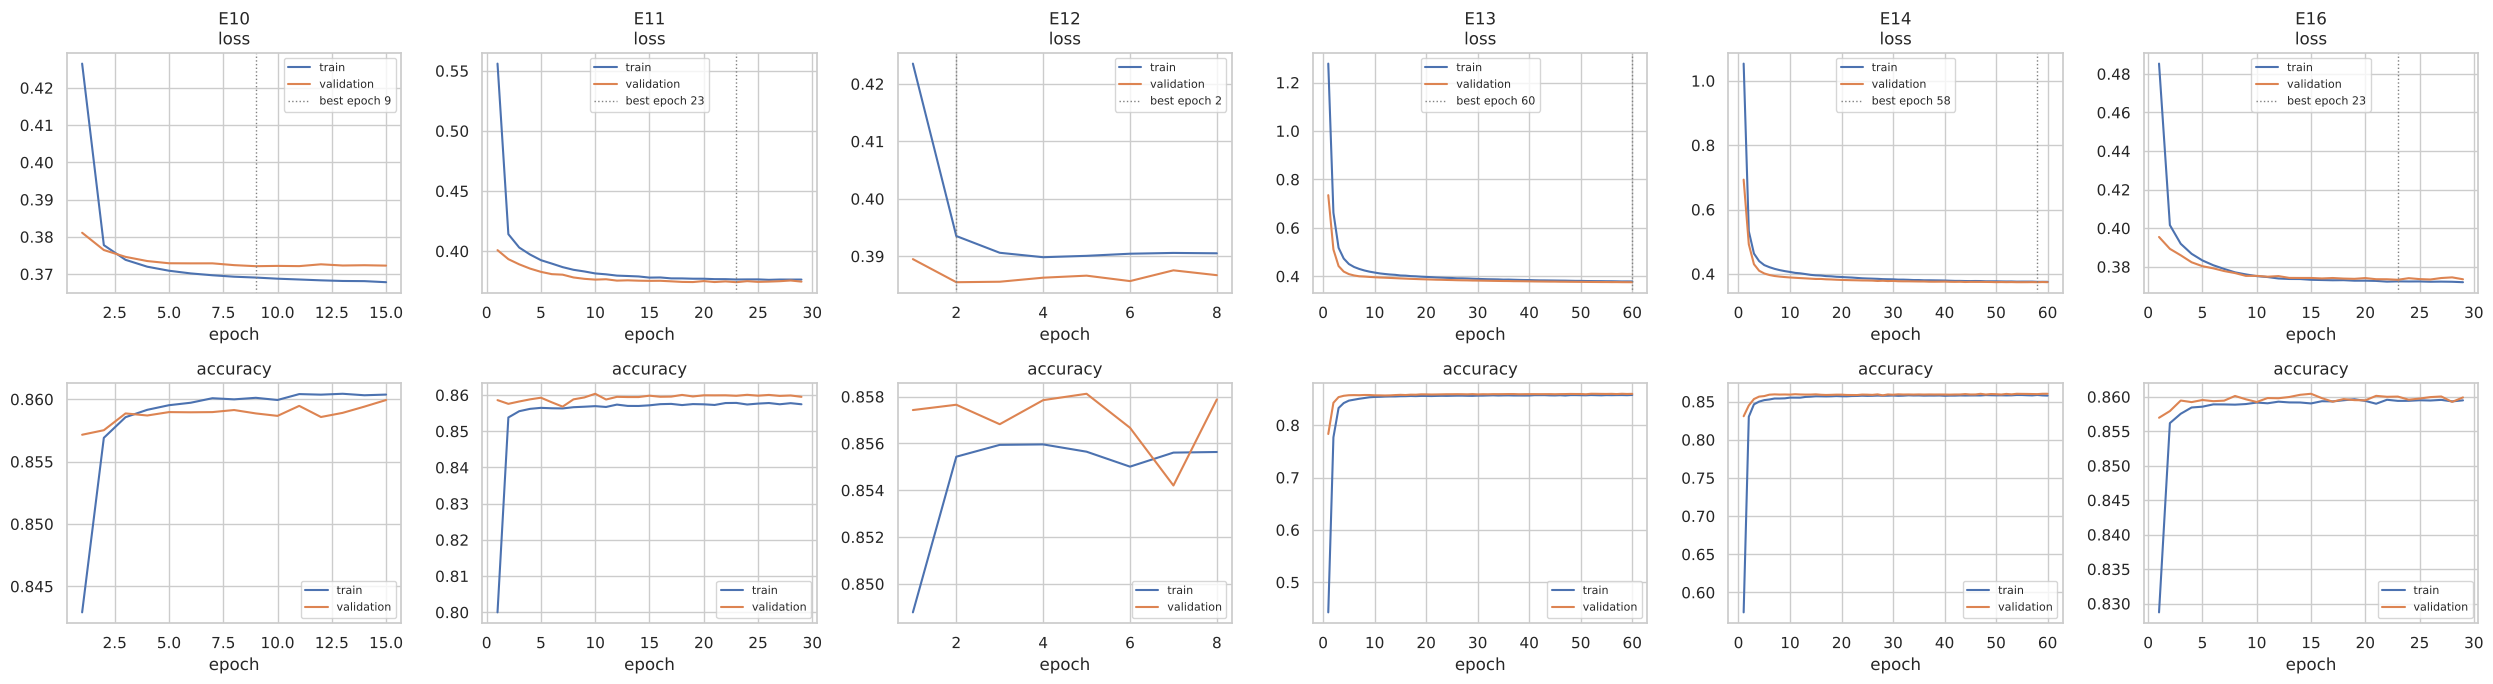

In [ ]:
fig = ev.plot_learning_curves({k: histories[k] for k in ["E10", "E11", "E12", "E13", "E14", "E16"]},
                              path=FIG / "fig05_keras_learning_curves.png")

**Interpretation.** * **E10 (Sequential baseline):** the 32-unit network (1,763 trainable parameters) early-stops at epoch 9 with almost no generalisation gap (training loss 0.3691 vs validation 0.3721). It reaches macro AP 0.4772, above logistic regression but below boosting.
* **E11 (regularised Sequential):** the 128-64-32 network trains for 29 epochs, with the best epoch at 23, and reaches macro AP 0.4791. Its training loss (0.3764) sits *above* its validation loss (0.3742) because dropout and L2 penalties are active only during training. The curves show no overfitting, so the extra capacity is not being wasted, but it also buys little.
* **E12 (learning rate 1e-2):** optimisation becomes unstable. Validation loss is lowest at epoch 2 and then oscillates, so early stopping halts at epoch 8, and macro AP drops to 0.4728.
* **E13 (learning rate 1e-4):** too slow for the epoch budget. Validation loss is still falling at epoch 60, the cap (best epoch 60), and training took about twice as long as E11 (216 s vs 112 s) for a similar macro AP (0.4793). Learning rate 1e-3 is the efficient middle ground.
* **E14 (batch size 4096):** with 8 times fewer updates per epoch, the model needs almost the full 60 epochs (best epoch 58) to reach the same macro AP (0.4791). Larger batches do not improve the solution here; they only change how quickly it is reached.
* **E15 (class weights):** the softened weights (0.625 / 4.37 / 1.60) raise diabetes recall from 0.155 to 0.500 and macro-F1 to 0.454, while macro AP stays essentially unchanged (0.4785). Even so, prediabetes is still never the argmax class.
* **E16/E17 (Functional wide-and-deep):** this is the best deep model (macro AP 0.4799, ROC-AUC 0.7956), essentially tied with E11 and E13. Engineered features (E17, 0.4797) again add nothing.

Across all architectures, validation macro AP stays within a narrow 0.473–0.480 band. That suggests the limit lies in the information the survey variables carry, not in network capacity.

**Learning curve for the boosting model.** Gradient boosting has no epochs, but its staged predictions give the equivalent diagnostic: training versus validation log-loss as trees are added.

final train loss 0.3571 | final val loss 0.3697 | min val loss 0.3696


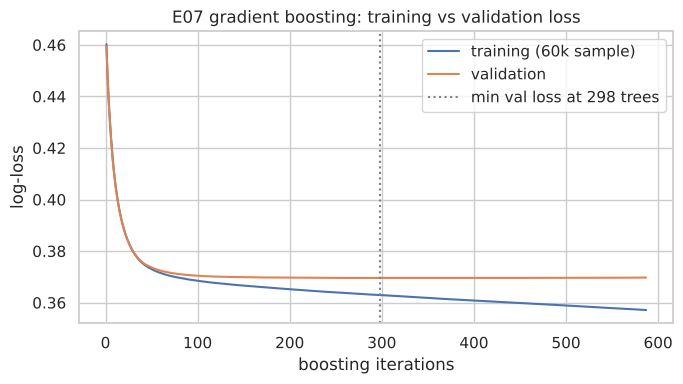

In [ ]:
from sklearn.metrics import log_loss
best_trad_pipe = fitted["E07"]
pre_fitted = tm.preprocessing_part(best_trad_pipe)
hgb_model = best_trad_pipe[-1]
sub_idx = X_tr.sample(60_000, random_state=SEED).index
Xtr_sub_t = pre_fitted.transform(X_tr.loc[sub_idx]); ytr_sub = y_tr.loc[sub_idx]
Xva_t = pre_fitted.transform(X_va)
stages = np.arange(1, hgb_model.n_iter_ + 1)
tr_loss = [log_loss(ytr_sub, p, labels=[0, 1, 2]) for p in hgb_model.staged_predict_proba(Xtr_sub_t)]
va_loss = [log_loss(y_va, p, labels=[0, 1, 2]) for p in hgb_model.staged_predict_proba(Xva_t)]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(stages, tr_loss, label="training (60k sample)"); ax.plot(stages, va_loss, label="validation")
ax.axvline(stages[int(np.argmin(va_loss))], color="grey", ls=":", label=f"min val loss at {stages[int(np.argmin(va_loss))]} trees")
ax.set(xlabel="boosting iterations", ylabel="log-loss", title="E07 gradient boosting: training vs validation loss"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "fig06_boosting_learning_curve.png", dpi=150)
print("final train loss %.4f | final val loss %.4f | min val loss %.4f" % (tr_loss[-1], va_loss[-1], min(va_loss)))

**Interpretation.** For the tuned boosting model, validation log-loss decreases monotonically and reaches its minimum (0.3696) at essentially the final iteration, while training loss ends at 0.3571. The small, stable gap (0.013) and the absence of a rising validation curve indicate mild variance but no overfitting: the strong regularisation selected by the search keeps 587 trees from memorising the data.

## 10. Hyperparameter Optimization and Experiment Tracking

All 17 experiments are now complete. This section summarises how the hyper-parameters were optimised and makes every run traceable:

* **Randomized search** (Section 8.3) for gradient boosting (16 candidates) and random forest (10 candidates), with 3-fold CV on training data only. The full candidate tables are saved to `reports/search_*.csv`.
* **Manual, one-factor-at-a-time variation** for the networks (Section 9): learning rate (E11 vs E12/E13), batch size (E14), regularisation and capacity (E10 vs E11), class weighting (E15), and architecture and features (E16/E17).
* **Tracking:** each run has a run ID and timestamp in `reports/experiment_log.jsonl`, a row in `reports/experiment_results.csv`, and a TensorBoard directory. Keras runs also log per-epoch curves.

Below I attach a one-line observation to every run, which completes the results table. I wrote these after reading the executed outputs. The notebook is fully seeded, and a second clean execution reproduced every metric exactly, so the observations hold on re-execution.

In [ ]:
OBSERVATIONS = {
    "E01": "Reference model: converges in 36 iterations; 0.86 accuracy hides 0 prediabetes and 0.18 diabetes recall under argmax.",
    "E02": "Without scaling, L-BFGS hits its 200-iteration cap (convergence warning), runs ~5x slower and is worse than E01 on every metric.",
    "E03": "Balanced weights vs E01: diabetes recall 0.18->0.59, prediabetes 0->0.31, but accuracy 0.645 and macro AP drops slightly; threshold moved, ranking not improved.",
    "E04": "Fully grown trees (mean depth ~39, ~13k leaves): macro AP above E01 but ROC-AUC below it, the signature of a high-variance learner.",
    "E05": "Boosting improves both macro AP and ROC-AUC over the forest: sequential bias reduction beats averaging deep trees here.",
    "E06": "Engineered features add only +0.0004 macro AP to E05; trees already form interactions such as age x BMI by splitting.",
    "E07": "Search picks the most regularised candidate (lr 0.036, 16 leaves, L2 4.34; train-fold 0.625 vs CV 0.475): best macro AP of all runs.",
    "E08": "Balanced weights on E07 repeat the E03 pattern: diabetes recall 0.66, prediabetes 0.28, macro AP lower.",
    "E09": "Shallower forest (depth 14, ~16% features per split) raises ROC-AUC 0.786->0.792 at unchanged macro AP: regularisation smooths mid-risk ranking.",
    "E10": "32-unit MLP early-stops at epoch 9 with a negligible train/val gap; beats LR slightly but trails boosting.",
    "E11": "Deeper MLP with BN/dropout/L2: small gain over E10; training loss above validation loss because regularisation is active only in training.",
    "E12": "lr 1e-2 is unstable (best epoch 2, oscillating validation loss) and loses macro AP versus E11.",
    "E13": "lr 1e-4 is still improving at the 60-epoch cap and takes ~2x E11's time for the same macro AP: too slow for the budget.",
    "E14": "Batch 4096 needs 58 of 60 epochs to match E11: fewer updates per epoch, no quality gain.",
    "E15": "Softened class weights raise diabetes recall 0.16->0.50 and macro-F1 to 0.454 with macro AP unchanged; prediabetes still never predicted.",
    "E16": "Wide-and-deep is the best deep model: the linear wide path keeps the additive signal, the deep path adds little on top.",
    "E17": "Engineered features give no gain on E16, consistent with E06.",
}
tracker.annotate(OBSERVATIONS)
print("Experiments executed and logged:", len(tracker.records))
print("Best gradient boosting CV candidates (macro AP):", hgb_cv.mean_test_score.head(3).round(4).tolist())
print("Best random forest CV candidates (macro AP):", rf_cv.mean_test_score.head(3).round(4).tolist())
runs = sorted(p.name for p in (LOGS / "tensorboard").iterdir())
print(f"TensorBoard run directories: {len(runs)}, e.g. {runs[0]} ... {runs[-1]}  (inspect with: tensorboard --logdir logs)")
tracker.results_frame()[["experiment_id", "run_id", "model", "imbalance_strategy", "avg_precision_macro", "observation"]]

Experiments executed and logged: 17
Best gradient boosting CV candidates (macro AP): [0.4753, 0.475, 0.4746]
Best random forest CV candidates (macro AP): [0.4748, 0.4746, 0.474]
TensorBoard run directories: 17, e.g. E01_20261018T073349Z ... E17_20261018T081347Z  (inspect with: tensorboard --logdir logs)


,experiment_id,run_id,model,imbalance_strategy,avg_precision_macro,observation
0,E01,E01_20261018T073349Z,Logistic regression,none,0.47043,Reference model: converges in 36 iterations; 0...
1,E02,E02_20261018T073416Z,Logistic regression (unscaled),none,0.46325,"Without scaling, L-BFGS hits its 200-iteration..."
2,E03,E03_20261018T073421Z,Logistic regression (balanced),class_weight=balanced,0.46575,Balanced weights vs E01: diabetes recall 0.18-...
3,E04,E04_20261018T073449Z,Random forest,none,0.47805,"Fully grown trees (mean depth ~39, ~13k leaves..."
4,E05,E05_20261018T073517Z,Gradient boosting,none,0.47941,Boosting improves both macro AP and ROC-AUC ov...
5,E06,E06_20261018T073551Z,Gradient boosting + engineered,none,0.47980,Engineered features add only +0.0004 macro AP ...
6,E07,E07_20261018T075447Z,Gradient boosting (tuned),none,0.48143,Search picks the most regularised candidate (l...
7,E08,E08_20261018T075614Z,"Gradient boosting (tuned, balanced)",class_weight=balanced,0.46865,Balanced weights on E07 repeat the E03 pattern...
8,E09,E09_20261018T080006Z,Random forest (tuned),none,0.47822,"Shallower forest (depth 14, ~16% features per ..."
9,E10,E10_20261018T080040Z,Sequential MLP baseline,none,0.47720,32-unit MLP early-stops at epoch 9 with a negl...


## 11. Model Evaluation and Comparison

### 11.1 Validation comparison of all experiments

,experiment_id,model,features,imbalance_strategy,train_seconds,accuracy,balanced_accuracy,f1_macro,roc_auc_ovr_macro,avg_precision_macro,ap_prediabetes,ap_diabetes,recall_prediabetes,recall_diabetes
0,E01,Logistic regression,base (25),none,5.41,0.8576,0.3861,0.3974,0.7887,0.4704,0.0351,0.4126,0.0000,0.1800
1,E02,Logistic regression (unscaled),base (25),none,25.74,0.8561,0.3799,0.3890,0.7694,0.4632,0.0301,0.3997,0.0000,0.1600
2,E03,Logistic regression (balanced),base (25),class_weight=balanced,4.70,0.6449,0.5191,0.4230,0.7783,0.4658,0.0322,0.4018,0.3096,0.5873
3,E04,Random forest,base (25),none,26.26,0.8604,0.3768,0.3854,0.7862,0.4780,0.0330,0.4370,0.0000,0.1432
4,E05,Gradient boosting,base (25),none,26.41,0.8604,0.3924,0.4060,0.7918,0.4794,0.0341,0.4393,0.0000,0.1983
5,E06,Gradient boosting + engineered,base+engineered (31),none,32.60,0.8611,0.3925,0.4062,0.7922,0.4798,0.0350,0.4396,0.0000,0.1976
6,E07,Gradient boosting (tuned),base+engineered (31),none,83.85,0.8613,0.3923,0.4061,0.7953,0.4814,0.0360,0.4430,0.0000,0.1966
7,E08,"Gradient boosting (tuned, balanced)",base+engineered (31),class_weight=balanced,83.88,0.6381,0.5276,0.4219,0.7771,0.4686,0.0297,0.4122,0.2845,0.6557
8,E09,Random forest (tuned),base+engineered (31),none,52.85,0.8597,0.3750,0.3826,0.7921,0.4782,0.0346,0.4356,0.0000,0.1377
9,E10,Sequential MLP baseline,base (25),none,28.50,0.8589,0.3867,0.3984,0.7927,0.4772,0.0370,0.4297,0.0000,0.1802


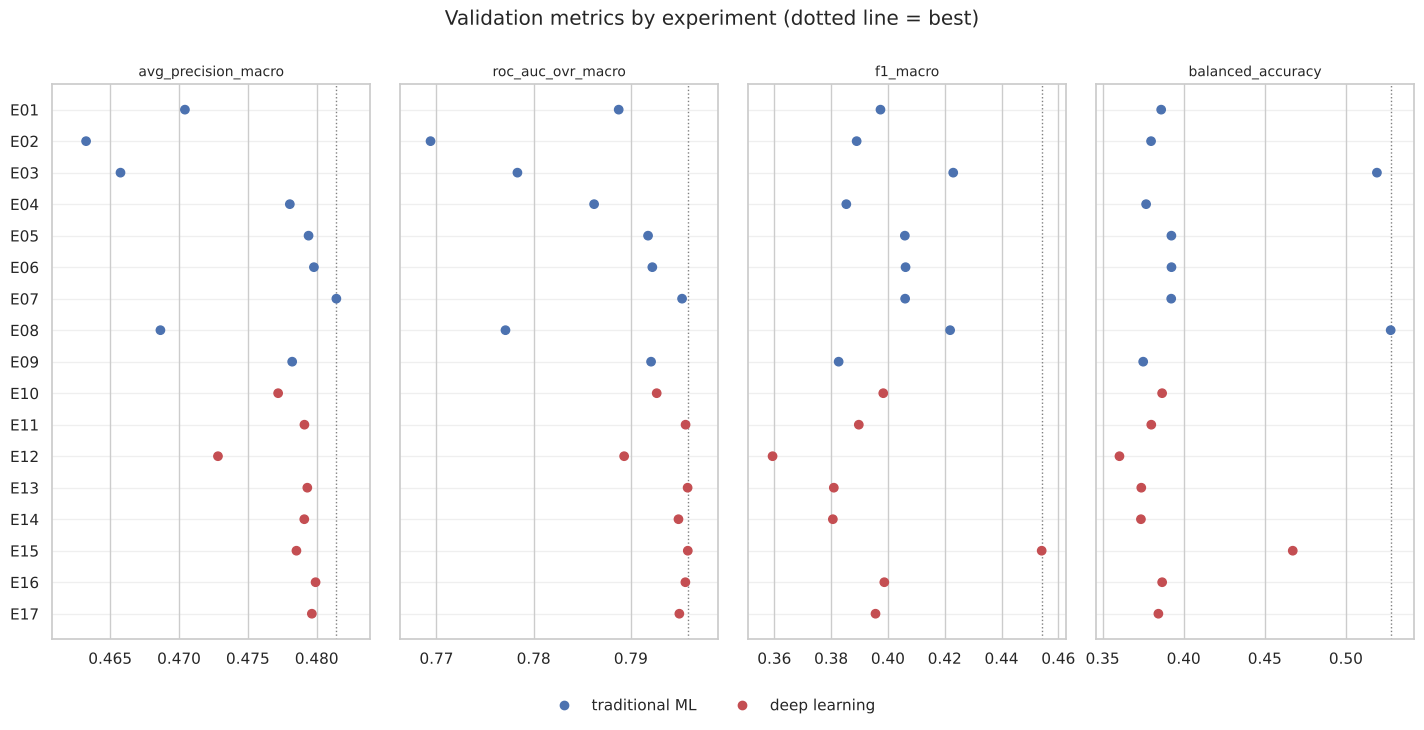

In [ ]:
results = tracker.results_frame()
show = ["experiment_id", "model", "features", "imbalance_strategy", "train_seconds", "accuracy", "balanced_accuracy",
        "f1_macro", "roc_auc_ovr_macro", "avg_precision_macro", "ap_prediabetes", "ap_diabetes", "recall_prediabetes", "recall_diabetes"]
display(results[show].round(4))
fig = ev.plot_model_comparison(results, ["avg_precision_macro", "roc_auc_ovr_macro", "f1_macro", "balanced_accuracy"],
                               path=FIG / "fig07_model_comparison.png")

**Interpretation.** The panels make the central result visible. Excluding the reweighted runs, every model lands within a macro average precision band of about 0.011 (0.4704 for logistic regression to 0.4814 for tuned boosting). ROC-AUC follows the same order: unscaled logistic regression and the reweighted models are lowest, and tuned boosting and the regularised networks are highest. Threshold-dependent metrics tell a different story. Macro-F1 and balanced accuracy are driven mainly by the imbalance strategy (E03, E08, E15), not by the model family, which shows that reweighting the loss shifts the decision threshold rather than improving the ranking.

The best traditional model (E07) edges out the best deep model (E16) by 0.0015 macro AP. The differences between the strong models are small, but they are consistent across the boosting variants. The ranking of model families is clear even where the absolute gaps are modest.

### 11.2 Model selection and decision rule

I select one traditional and one deep-learning model by **validation macro average precision**. With argmax decisions, both models almost never predict the minority classes, because the probability of prediabetes rarely exceeds that of "no diabetes" for anyone. A 0.5-style default threshold is therefore inappropriate. I rescale class probabilities with per-class weights tuned **on validation** to maximise macro-F1, which is the multiclass analogue of moving a binary threshold. The test set is still unused at this point.

In [ ]:
trad = results[results.paradigm == "traditional ML"].sort_values("avg_precision_macro", ascending=False).iloc[0]
deep = results[results.paradigm == "deep learning"].sort_values("avg_precision_macro", ascending=False).iloc[0]
BEST_TRAD, BEST_DEEP = trad.experiment_id, deep.experiment_id
print("Selected traditional model:", BEST_TRAD, trad.model, "| val macro-AP %.4f" % trad.avg_precision_macro)
print("Selected deep model:       ", BEST_DEEP, deep.model, "| val macro-AP %.4f" % deep.avg_precision_macro)

decision = {}
for eid in [BEST_TRAD, BEST_DEEP, "E01"]:
    w, score, table = ev.tune_decision_weights(y_va.values, val_probas[eid])
    base = ev.compute_metrics(y_va, val_probas[eid])["f1_macro"]
    decision[eid] = w
    print(f"{eid}: weights (none, prediabetes, diabetes) = {w.tolist()} | val macro-F1 argmax {base:.4f} -> tuned {score:.4f}")

Selected traditional model: E07 Gradient boosting (tuned) | val macro-AP 0.4814
Selected deep model:        E16 Functional wide-and-deep | val macro-AP 0.4799


E07: weights (none, prediabetes, diabetes) = [1.0, 15.0, 2.5] | val macro-F1 argmax 0.4061 -> tuned 0.4690


E16: weights (none, prediabetes, diabetes) = [1.0, 15.0, 2.5] | val macro-F1 argmax 0.3987 -> tuned 0.4693


E01: weights (none, prediabetes, diabetes) = [1.0, 20.0, 3.0] | val macro-F1 argmax 0.3974 -> tuned 0.4651


**Interpretation.** On validation macro average precision, the selected models are tuned gradient boosting (E07, 0.4814) and the Functional wide-and-deep network (E16, 0.4799). Tuning the decision weights on validation raises macro-F1 substantially for all three final candidates: E07 from 0.406 to 0.469, E16 from 0.399 to 0.469, and logistic regression from 0.397 to 0.465.

The chosen multipliers are similar across models: prediabetes 15–20 and diabetes 2.5–3, relative to 1 for no diabetes. In other words, a respondent should be called "prediabetes" or "diabetes" well before that class becomes the single most probable one. With the first, coarser grid, the prediabetes weight landed on the grid's upper edge (20). I widened the grid to 80 so that the optimum (15 for E07 and E16, 20 for E01) is now interior. The validation surface near the optimum is flat: the next-best weight pairs score within 0.002 macro-F1.

### 11.3 Final evaluation on the held-out test set

The three final models are each evaluated **once** on the same independent test set: logistic regression (E01) as the interpretable reference, plus the selected traditional and deep-learning models, all with their validation-tuned decision weights.

In [ ]:
FEATS = {eid: ("eng" if "engineered" in results.set_index("experiment_id").loc[eid, "features"] else "base") for eid in results.experiment_id}
def test_proba(eid):
    if eid in fitted:
        return fitted[eid].predict_proba(X_te)
    return keras_models[eid].predict(dl.make_tf_dataset(A[FEATS[eid]]["te"], batch_size=4096), verbose=0)

final_ids = ["E01", BEST_TRAD, BEST_DEEP]
names = {eid: f"{eid} {results.set_index('experiment_id').loc[eid, 'model']}" for eid in final_ids}
test_probas, test_preds, rows = {}, {}, []
for eid in final_ids:
    p = test_proba(eid); test_probas[names[eid]] = p
    yhat = ev.predict_with_weights(p, decision[eid]); test_preds[eid] = yhat
    m = ev.compute_metrics(y_te, p, y_pred=yhat)
    mw = ev.compute_metrics(y_te, p, y_pred=yhat, sample_weight=m_te["_LLCPWT"].values)
    rows.append({"model": names[eid], **{k: m[k] for k in ["accuracy", "balanced_accuracy", "precision_macro", "recall_macro",
                 "f1_macro", "roc_auc_ovr_macro", "avg_precision_macro", "recall_prediabetes", "precision_prediabetes",
                 "recall_diabetes", "precision_diabetes"]},
                 "weighted_f1_macro": mw["f1_macro"], "weighted_roc_auc": mw["roc_auc_ovr_macro"], "weighted_recall_diabetes": mw["recall_diabetes"]})
test_table = pd.DataFrame(rows).set_index("model")
test_table.to_csv(ROOT / "reports" / "test_results.csv")
test_table.T.round(4)

model,E01 Logistic regression,E07 Gradient boosting (tuned),E16 Functional wide-and-deep
accuracy,0.8053,0.8229,0.8236
balanced_accuracy,0.4803,0.4783,0.4745
precision_macro,0.4516,0.4607,0.4591
recall_macro,0.4803,0.4783,0.4745
f1_macro,0.4624,0.4683,0.4657
roc_auc_ovr_macro,0.7942,0.8004,0.8005
avg_precision_macro,0.4690,0.4790,0.4775
recall_prediabetes,0.0719,0.0468,0.0416
precision_prediabetes,0.0437,0.0482,0.0465
recall_diabetes,0.5024,0.5002,0.4917


E01 Logistic regression


,precision,recall,f1-score,support
No diabetes,0.917,0.867,0.891,56357.000
Prediabetes,0.044,0.072,0.054,1154.000
Diabetes,0.394,0.502,0.442,8588.000
accuracy,0.805,0.805,0.805,0.805
macro avg,0.452,0.480,0.462,66099.000
weighted avg,0.834,0.805,0.818,66099.000


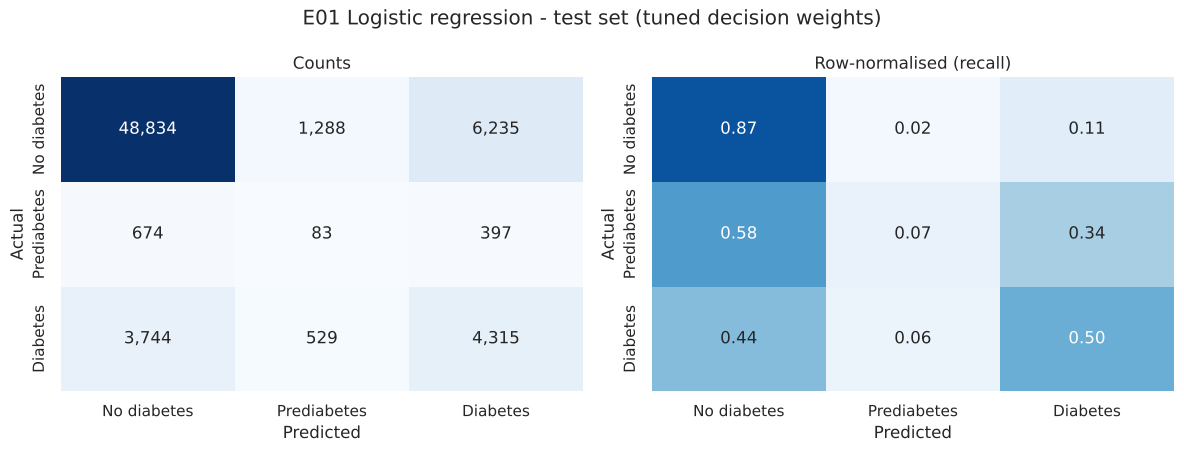

E07 Gradient boosting (tuned)


,precision,recall,f1-score,support
No diabetes,0.914,0.888,0.901,56357.000
Prediabetes,0.048,0.047,0.047,1154.000
Diabetes,0.420,0.500,0.457,8588.000
accuracy,0.823,0.823,0.823,0.823
macro avg,0.461,0.478,0.468,66099.000
weighted avg,0.835,0.823,0.828,66099.000


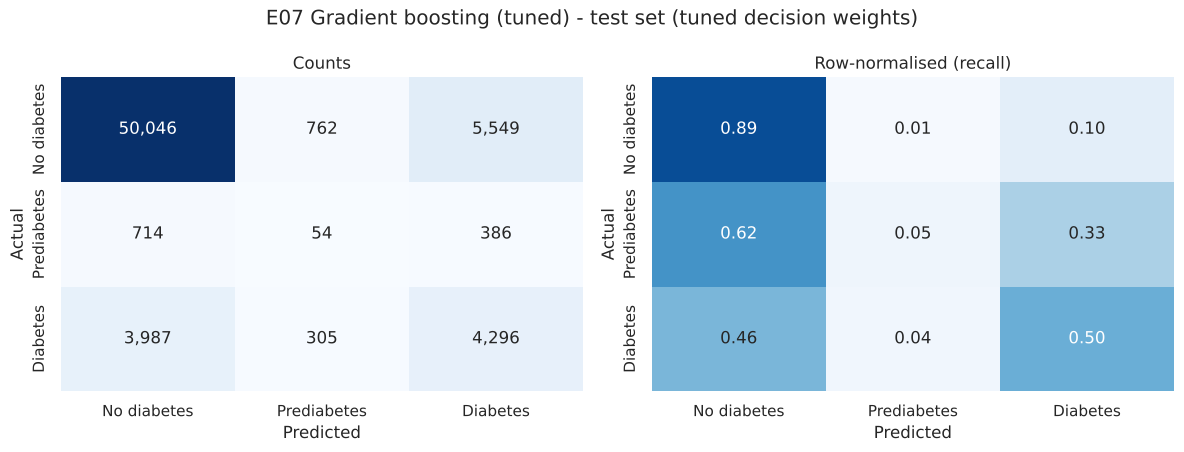

E16 Functional wide-and-deep


,precision,recall,f1-score,support
No diabetes,0.913,0.890,0.901,56357.000
Prediabetes,0.047,0.042,0.044,1154.000
Diabetes,0.418,0.492,0.452,8588.000
accuracy,0.824,0.824,0.824,0.824
macro avg,0.459,0.475,0.466,66099.000
weighted avg,0.833,0.824,0.828,66099.000


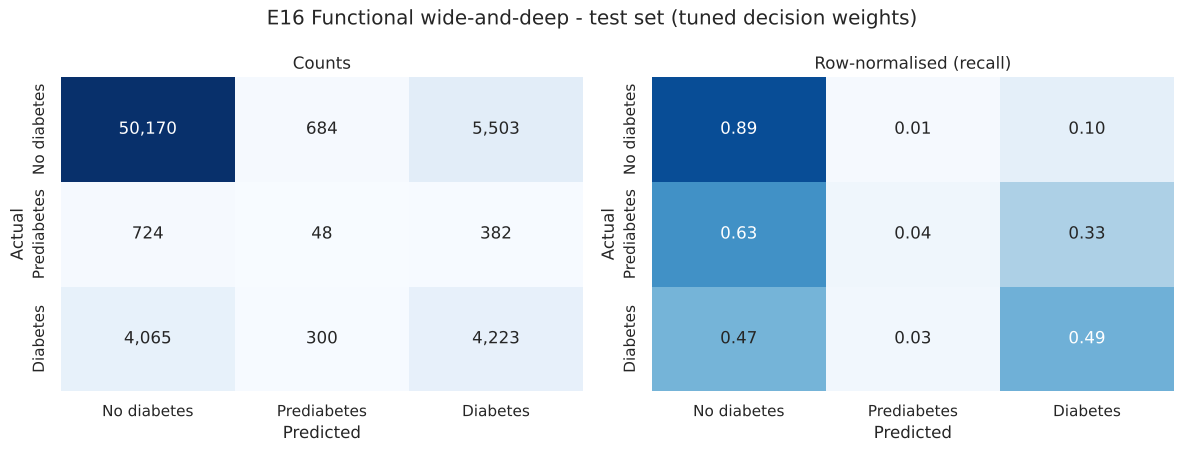

In [ ]:
for eid in final_ids:
    print(names[eid]); display(ev.report_frame(y_te, test_preds[eid]))
    ev.plot_confusion_matrices(y_te, test_preds[eid], title=f"{names[eid]} - test set (tuned decision weights)",
                               path=FIG / f"fig08_confusion_{eid}.png")
    plt.show()

**Interpretation.** On the untouched test set, the three final models are very close:

| | Macro ROC-AUC | Macro AP | Macro-F1 |
|---|---|---|---|
| Gradient boosting (E07) | 0.8004 | 0.4790 | 0.468 |
| Wide-and-deep (E16) | 0.8005 | 0.4775 | 0.466 |
| Logistic regression (E01) | 0.7942 | 0.4690 | 0.462 |

The test values agree with validation (E07 validation macro AP was 0.4814), so selecting on validation did not overfit it.

For the **diabetes** class, the tuned rule recovers half of the cases. Boosting finds 4,296 of 8,588 (recall 0.500, precision 0.420); logistic regression has a similar recall (0.502) but lower precision (0.394). The confusion matrix shows where the remaining cases go: 3,987 diabetes cases are labelled "no diabetes" and 305 "prediabetes". In the other direction, 5,549 people without diabetes are flagged as diabetic.

**Prediabetes** remains essentially unsolved. Boosting labels 54 of 1,154 cases correctly (recall 0.047, precision 0.048). It assigns 714 to "no diabetes" and 386 to "diabetes", so prediabetes cases are spread across both neighbouring classes. The survey-weighted metrics tell the same story (weighted macro ROC-AUC 0.828 for boosting), so the conclusions are not an artefact of the sample's age structure.

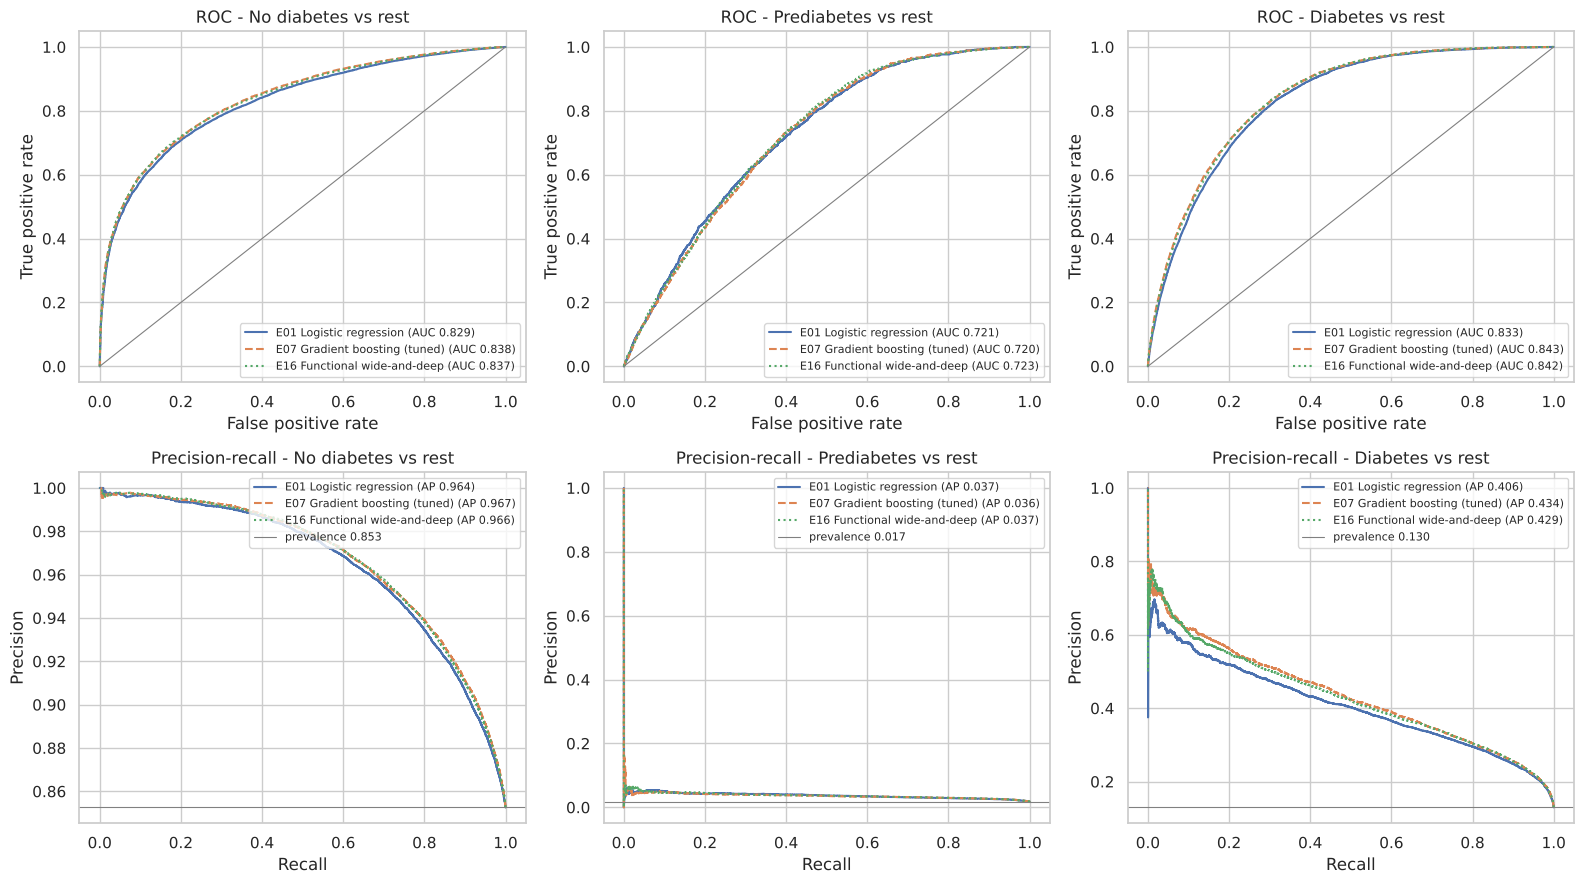

In [ ]:
fig = ev.plot_roc_pr_curves(y_te, test_probas, path=FIG / "fig09_roc_pr_test.png")

**Interpretation.** The ROC curves of the three models almost overlap. Diabetes-versus-rest AUC is 0.843 for boosting, 0.842 for wide-and-deep and 0.833 for logistic regression, and the curves for "no diabetes" are similar. The precision–recall curves are more revealing:

* **Diabetes:** average precision is 0.434 (boosting) against a prevalence baseline of 0.130. The models concentrate cases about three-fold, but precision falls below 0.5 once recall passes about 0.3.
* **Prediabetes:** average precision is only 0.036–0.037 against a prevalence of 0.017, even though its ROC-AUC (0.72) looks respectable.

The prediabetes result illustrates why ROC curves can flatter performance on rare classes: a moderate ROC-AUC co-exists with precision that never meaningfully leaves the floor.

### 11.4 Binary screening view: diabetes versus not

In a screening application, the most consequential decision is whether to flag someone as likely to have diabetes. I convert the selected model's diabetes probability into a binary flag. The threshold is chosen on **validation** to maximise F2, which weights recall twice as heavily as precision: a missed case (false negative) leaves a person unaware of a treatable condition, while a false positive costs an unnecessary but cheap confirmatory HbA1c or fasting-glucose test. I report the consequences on the test set alongside the default 0.5 threshold.

In [ ]:
score_va = val_probas[BEST_TRAD][:, 2]; score_te = test_probas[names[BEST_TRAD]][:, 2]
thr, f2_va, p_va, r_va = ev.screening_threshold((y_va == 2).astype(int), score_va, beta=2)
print(f"Validation-selected threshold: {thr:.3f} (val F2 {f2_va:.3f}, precision {p_va:.3f}, recall {r_va:.3f})")
screen = pd.DataFrame({
    "default_0.5": ev.binary_screening_metrics((y_te == 2).astype(int), score_te, 0.5),
    "F2_threshold": ev.binary_screening_metrics((y_te == 2).astype(int), score_te, thr),
    "F2_threshold_survey_weighted": ev.binary_screening_metrics((y_te == 2).astype(int), score_te, thr, sample_weight=m_te["_LLCPWT"].values),
}).T
screen.to_csv(ROOT / "reports" / "screening_results.csv")
screen.round(3)

Validation-selected threshold: 0.112 (val F2 0.606, precision 0.284, recall 0.847)


,threshold,sensitivity,specificity,ppv,npv,f2,flag_rate,tp,fp,fn,tn
default_0.5,0.500,0.168,0.982,0.581,0.888,0.195,0.038,1440.00,1039.000,7148.000,5.647200e+04
F2_threshold,0.112,0.847,0.680,0.283,0.967,0.606,0.389,7273.00,18432.000,1315.000,3.907900e+04
F2_threshold_survey_weighted,0.112,0.809,0.764,0.287,0.971,0.593,0.296,3199271.62,7967161.974,757765.149,2.579037e+07


**Interpretation.** At the default 0.5 threshold, the model flags only 3.8% of respondents and misses 83% of diabetes cases (sensitivity 0.168), although its flags are usually right (PPV 0.581). The validation-selected F2 threshold of 0.112 reverses the balance. On the test set it detects 7,273 of 8,588 cases (sensitivity 0.847), with specificity 0.680 and NPV 0.967, but it flags 38.9% of respondents. Fewer than three in ten flags are true cases (PPV 0.283), and there are 18,432 false positives for 1,315 missed cases.

Under survey weighting, sensitivity is 0.809 and 29.6% of the weighted population is flagged. The sample over-represents older adults, among whom flags are more common.

Whether this trade-off is acceptable is a policy question, not a modelling one. A follow-up HbA1c test is cheap, so an F2-style rule is defensible for outreach. Even so, a rule that flags a third of adults is only useful if a confirmatory test is affordable at that scale.

## 12. Error Analysis and Explainability

### 12.1 Where do the errors come from?

I compare correctly identified and missed diabetes cases on key indicators, and I check where true prediabetes cases end up. A model that misses diabetes mostly among young, normal-BMI respondents is failing in a predictable way; a model that misses cases with classic risk profiles would be failing for a different reason.

In [ ]:
yhat = test_preds[BEST_TRAD]
dia = (y_te == 2).values
groups = pd.Series(np.where(dia & (yhat == 2), "diabetes: detected", np.where(dia, "diabetes: missed", None)))
profile_cols = ["age", "bmi", "high_bp", "high_chol", "gen_health", "cardiometabolic_count", "diff_walk", "checkup_recency"]
Xte_eng = fe.ClinicalFeatureEngineer().fit_transform(X_te)
prof = Xte_eng[profile_cols].groupby(groups).mean().T
prof["non-diabetes (reference)"] = Xte_eng.loc[(y_te == 0).values, profile_cols].mean()
display(prof.round(2))
pre = (y_te == 1).values
print("Where true prediabetes cases are predicted:",
      pd.Series(yhat[pre]).map(dict(enumerate(prep.CLASS_NAMES))).value_counts(normalize=True).round(3).to_dict())
fp = (yhat == 2) & (y_te.values == 0)
print("Profile of false-positive diabetes flags vs true negatives (mean cardiometabolic count): %.2f vs %.2f"
      % (Xte_eng.loc[fp, "cardiometabolic_count"].mean(), Xte_eng.loc[(yhat == 0) & (y_te.values == 0), "cardiometabolic_count"].mean()))

,diabetes: detected,diabetes: missed,non-diabetes (reference)
age,66.05,62.90,53.98
bmi,34.38,28.84,27.45
high_bp,0.92,0.58,0.35
high_chol,0.79,0.51,0.33
gen_health,3.80,2.87,2.44
cardiometabolic_count,2.34,1.27,0.79
diff_walk,0.54,0.22,0.14
checkup_recency,1.13,1.25,1.52


Where true prediabetes cases are predicted: {'No diabetes': 0.619, 'Diabetes': 0.334, 'Prediabetes': 0.047}
Profile of false-positive diabetes flags vs true negatives (mean cardiometabolic count): 2.15 vs 0.63


**Interpretation.** Missed diabetes cases look much more like people without diabetes than like detected cases:

| Mean value | Detected cases | Missed cases | No diabetes |
|---|---|---|---|
| BMI | 34.4 | 28.8 | 27.5 |
| Diagnosed cardiometabolic conditions | 2.34 | 1.27 | 0.79 |
| Self-rated health (5 = poor) | 3.80 | 2.87 | 2.44 |
| Age | 66.1 | 62.9 | 54.0 |

The false positives mirror this. People flagged as diabetic who report no diabetes have an average of 2.15 cardiometabolic conditions, versus 0.63 for true negatives. Their profile resembles diabetes, and some may well be undiagnosed cases, which the self-reported label cannot reveal. So most errors are not random noise. They arise where the survey indicators genuinely overlap: people with diabetes and few other conditions, and people without a diabetes diagnosis but with a high-risk profile.

Prediabetes illustrates the same point. Its cases are predicted as "no diabetes" 61.9% of the time and "diabetes" 33.4%, and only 4.7% are recognised. With these indicators, prediabetes is not a distinct region of feature space but an intermediate zone between its neighbours.

### 12.2 Explainability

I use two complementary methods on the selected boosting model:

* **Permutation importance** on a 20,000-row validation sample: how much macro average precision drops when one raw feature is shuffled. It is model-agnostic and measured on held-out data, but correlated features share credit.
* **SHAP (TreeExplainer)** on 2,000 validation rows, which decomposes each prediction into additive feature contributions (in log-odds) for the diabetes class.

For contrast, I also show the standardised logistic-regression coefficients (diabetes vs. no diabetes). None of these measures is causal: they describe what the model relies on, in a cross-sectional survey where diabetes can also cause the "predictors", such as poorer self-rated health or a recent check-up.

permutation importance computed in 134s


,importance_mean,importance_std
bmi,0.0347,0.0017
gen_health,0.0287,0.0010
age,0.0165,0.0015
high_bp,0.0109,0.0009
high_chol,0.0088,0.0010
kidney_disease,0.0052,0.0004
checkup_recency,0.0035,0.0004
sex_female,0.0027,0.0003
heavy_drinker,0.0016,0.0005
income,0.0016,0.0005


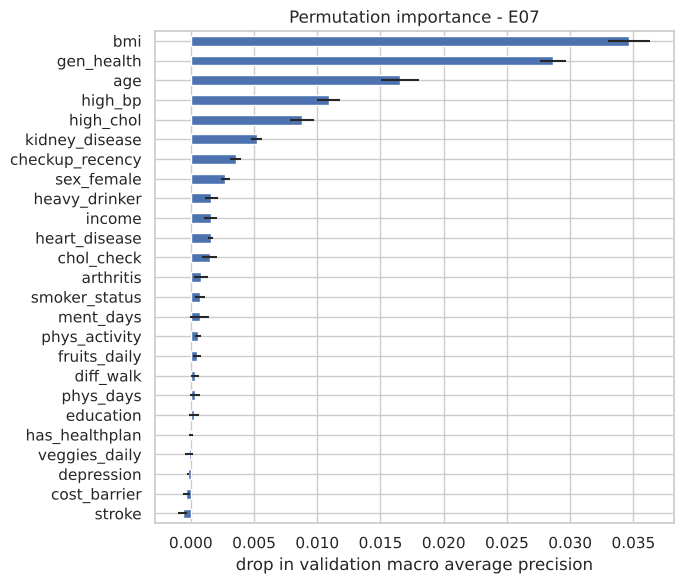

In [ ]:
from sklearn.inspection import permutation_importance
Xva_s = X_va.sample(20_000, random_state=SEED); yva_s = y_va.loc[Xva_s.index]
t0 = time.perf_counter()
perm = permutation_importance(fitted[BEST_TRAD], Xva_s, yva_s, scoring=ev.MACRO_AP_SCORER, n_repeats=5, random_state=SEED, n_jobs=1)
perm_df = pd.DataFrame({"importance_mean": perm.importances_mean, "importance_std": perm.importances_std}, index=X_va.columns)
perm_df = perm_df.sort_values("importance_mean", ascending=False)
perm_df.to_csv(ROOT / "reports" / "permutation_importance.csv")
print(f"permutation importance computed in {time.perf_counter()-t0:.0f}s")
fig, ax = plt.subplots(figsize=(7, 6))
perm_df.importance_mean.iloc[::-1].plot.barh(xerr=perm_df.importance_std.iloc[::-1], ax=ax, color="#4C72B0")
ax.set(xlabel="drop in validation macro average precision", title=f"Permutation importance - {BEST_TRAD}")
fig.tight_layout(); fig.savefig(FIG / "fig10_permutation_importance.png", dpi=150)
perm_df.head(10).round(4)

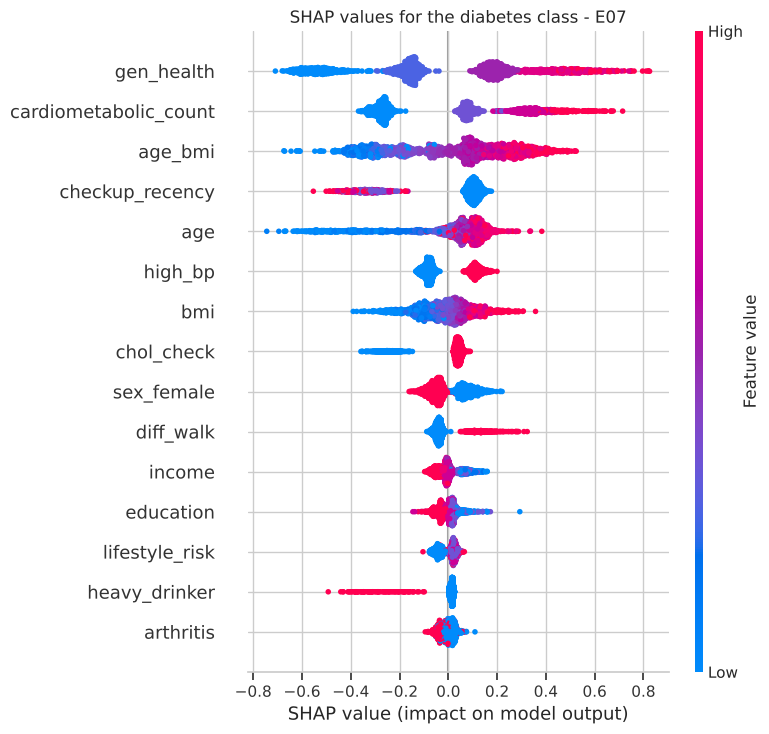

gen_health               0.3025
cardiometabolic_count    0.2506
age_bmi                  0.2091
checkup_recency          0.1633
age                      0.1323
high_bp                  0.0960
bmi                      0.0842
chol_check               0.0720
sex_female               0.0663
diff_walk                0.0562
income                   0.0359
education                0.0313
dtype: float64

In [ ]:
import shap
pre_best = tm.preprocessing_part(fitted[BEST_TRAD])
Xs = pre_best.transform(X_va.sample(2_000, random_state=SEED))
feat_names = list(pre_best[-1].get_feature_names_out())
explainer = shap.TreeExplainer(fitted[BEST_TRAD][-1])
sv = explainer.shap_values(Xs)
sv_dia = sv[:, :, 2] if np.ndim(sv) == 3 else sv[2]
plt.figure()
shap.summary_plot(sv_dia, Xs, feature_names=feat_names, max_display=15, show=False)
plt.title(f"SHAP values for the diabetes class - {BEST_TRAD}")
plt.tight_layout(); plt.savefig(FIG / "fig11_shap_diabetes.png", dpi=150, bbox_inches="tight"); plt.show()
shap_rank = pd.Series(np.abs(sv_dia).mean(axis=0), index=feat_names).sort_values(ascending=False)
shap_rank.head(12).round(4)

In [ ]:
lr = fitted["E01"][-1]
lr_names = list(fitted["E01"][0].get_feature_names_out())
coef = pd.DataFrame({"diabetes_vs_none": lr.coef_[2] - lr.coef_[0], "prediabetes_vs_none": lr.coef_[1] - lr.coef_[0]}, index=lr_names)
coef["odds_ratio_per_SD_diabetes"] = np.exp(coef.diabetes_vs_none)
coef = coef.reindex(coef.diabetes_vs_none.abs().sort_values(ascending=False).index)
coef.to_csv(ROOT / "reports" / "logistic_coefficients.csv")
coef.head(12).round(3)

,diabetes_vs_none,prediabetes_vs_none,odds_ratio_per_SD_diabetes
gen_health,0.546,0.277,1.726
smoker_status_current_someday,-0.503,-0.722,0.605
smoker_status_current_daily,-0.489,-0.792,0.613
age,0.447,0.361,1.563
smoker_status_never,-0.428,-0.763,0.652
smoker_status_former,-0.421,-0.778,0.656
bmi,0.404,0.322,1.497
high_bp,0.374,0.180,1.453
smoker_status_missing,-0.311,-0.372,0.733
chol_check,0.275,0.154,1.316


**Interpretation.** The three explanation methods agree on the core signals but rank them differently:

* **Permutation importance** (raw input features, including their effect through engineered features) ranks BMI first (drop in macro AP 0.0347), then general health (0.0287), age (0.0165), high blood pressure (0.0109) and high cholesterol (0.0088). All other features contribute less than 0.006 each. The model relies on a handful of variables.
* **SHAP**, computed on the transformed inputs, spreads that credit onto the engineered features the boosting model actually splits on. General health (mean |SHAP| 0.30) comes first, followed by the cardiometabolic count (0.25), age × BMI (0.21) and check-up recency (0.16). BMI's own SHAP value is modest (0.08) because the age × BMI interaction carries much of its effect. This shows how correlated or derived features share credit, so no single ranking should be read as definitive.
* **Logistic regression** gives the clearest directions. Per standard deviation, the odds of diabetes versus none rise by about 1.73 for poorer general health, 1.56 for age, 1.50 for BMI and 1.45 for high blood pressure.

Several signals reflect reverse causation rather than risk. A more recent check-up is associated with *higher* odds (odds ratio 0.79 per SD of time since the last check-up), and SHAP shows the same direction. A cholesterol check carries positive weight. Heavy drinking pushes predictions *down*. The smoking dummies all have negative coefficients only because they are measured relative to the intercept; their differences from each other are small. These are features of how a diagnosis changes behaviour and health-care contact, not of what causes diabetes. They are useful for classification, but any causal reading would be wrong.

### 12.3 Subgroup performance

I check whether diabetes detection differs across sex, age, race/ethnicity and income on the test set, using the selected model and its tuned decision rule. Race/ethnicity was never a model input. Subgroups with fewer than 30 diabetes cases are flagged as unreliable.

In [ ]:
age_band = pd.cut(X_te["age"], [17, 44, 64, 80], labels=["18-44", "45-64", "65+"])
sub_specs = {
    "sex": X_te["sex_female"].map({0.0: "Male", 1.0: "Female"}),
    "age": age_band.astype(str),
    "race/ethnicity": m_te["_RACEGR3"].map(prep.RACE_LABELS),
    "income": pd.cut(X_te["income"], [0, 3, 6, 8], labels=["<$20k", "$20-50k", "$50k+"]).astype(str).replace("nan", np.nan),
}
sub_tables = []
for dim, g in sub_specs.items():
    t = ev.subgroup_metrics(y_te.values, test_probas[names[BEST_TRAD]], test_preds[BEST_TRAD], g)
    t.insert(0, "dimension", dim); sub_tables.append(t)
subgroups = pd.concat(sub_tables, ignore_index=True)
subgroups.to_csv(ROOT / "reports" / "subgroup_metrics.csv", index=False)
subgroups.round(3)

,dimension,group,n,diabetes_cases,diabetes_prevalence,recall_diabetes,precision_diabetes,f1_macro,reliable,roc_auc_diabetes
0,sex,Female,37957,4715,0.124,0.486,0.417,0.467,True,0.846
1,sex,Male,28142,3873,0.138,0.517,0.423,0.470,True,0.839
2,age,45-64,25676,3359,0.131,0.485,0.418,0.467,True,0.832
3,age,65+,22944,4697,0.205,0.544,0.421,0.449,True,0.767
4,age,18-44,17479,532,0.030,0.209,0.429,0.432,True,0.877
5,race/ethnicity,White NH,50483,6103,0.121,0.494,0.404,0.465,True,0.840
6,race/ethnicity,Hispanic,5223,755,0.145,0.518,0.474,0.481,True,0.866
7,race/ethnicity,Black NH,5127,1053,0.205,0.543,0.462,0.457,True,0.813
8,race/ethnicity,Other NH,2946,369,0.125,0.447,0.498,0.499,True,0.869
9,race/ethnicity,Multiracial NH,1241,163,0.131,0.540,0.440,0.461,True,0.870


**Interpretation.** Diabetes detection is broadly similar by sex: recall is 0.486 for women and 0.517 for men, with ROC-AUC 0.846 and 0.839. The differences by age and income are larger:

* **Age.** Among adults aged 18–44, ROC-AUC is the highest of any group (0.877), but recall is only 0.209. With a prevalence of 3%, few young people cross the single, population-wide decision rule. Among those aged 65+, recall is 0.544 but ROC-AUC is the lowest (0.767), because diabetes is common (20.5%) and harder to separate from the comorbidities of ageing.
* **Income.** Recall rises from 0.370 in the $50k+ group to 0.631 below $20k, mostly tracking prevalence (9.0% vs 19.9%), while ROC-AUC falls from 0.856 to 0.816.
* **Race/ethnicity.** Black non-Hispanic respondents have the highest prevalence (20.5%) and the lowest ROC-AUC (0.813) among the race/ethnicity groups, against 0.840 for White and 0.866 for Hispanic respondents. Race was never an input, so this reflects how the other indicators relate to diabetes in each group.

These are descriptive disparities, not proof of unfairness. They show that a single threshold yields very different sensitivities across groups, and that groups with more diabetes are, in ranking terms, the hardest to classify. Any screening use would need group-aware threshold review and calibration checks.

## 13. Discussion and Conclusions

**Interpretation.** **Answer to the research question.** With 25 survey indicators, all model families reach a similar ceiling. On the held-out test set, macro ROC-AUC is about 0.80 and macro average precision about 0.48. The diabetes class is reasonably well ranked (ROC-AUC up to 0.843, AP 0.434 against a 13% baseline), while prediabetes is barely distinguishable (AP 0.036 against a 1.7% baseline).

**Traditional ML versus deep learning.** The hypothesis is supported in direction but with a small effect size. Tuned gradient boosting has the best threshold-free scores (validation macro AP 0.4814, test 0.4790). The best network, the wide-and-deep model, essentially ties it on ROC-AUC (0.8005 vs 0.8004) and trails slightly on AP (0.4775). Logistic regression trails both by about 0.01 AP. Notably, the network that worked best was the one that explicitly embedded a logistic regression, and engineered interactions added nothing to either paradigm. Most of the signal in these data is additive.

**Efficiency and interpretability.** Logistic regression trains in about 5 seconds and has directly readable coefficients. Boosting needs about 85 seconds plus an 18-minute search, and the neural networks 28–216 seconds per run plus careful learning-rate and epoch choices. The gains in exchange are about 0.01 macro AP and 0.006 macro ROC-AUC.

**What matters more than the algorithm.** The decision rule matters most. Default argmax decisions find fewer than one in five diabetes cases; validation-tuned weights find half; an F2 screening threshold finds 85%, at the cost of flagging 39% of respondents. Class weighting changes where the threshold sits rather than how well cases are ranked.

**Limits.** The main limits sit in the data, not the models. The labels are self-reported diagnoses, so undiagnosed diabetes and untested prediabetes are counted as negatives, and the false positives look like plausible undiagnosed cases. The data are cross-sectional, and several strong predictors (general health, check-up recency, cholesterol testing) partly reflect a diagnosis that has already happened. Detection also varies widely across age, income and racial groups under one threshold.

**What this means for rural sub-Saharan Africa.** Three findings carry over to the setting my mission targets.

* **A cheap model is enough.** Logistic regression is within about 0.01 AP of the best model, runs in milliseconds on any phone, and its coefficients can be explained to health workers. That suits community-health-worker tools far better than a model that needs a GPU or careful tuning.
* **The threshold is a resource decision.** Detecting 85% of cases meant flagging 39% of people, which only makes sense if confirmatory HbA1c or glucose tests are available for that many. Thresholds must be set with local clinic capacity in mind.
* **Labels and equity cannot be taken for granted.** Sensitivity differed sharply between groups, and "ever told" labels undercount people with poor access to care. That is exactly the situation of rural communities where most diabetes is undiagnosed. A model trained on such labels would learn to miss them.

So the responsible next step for Africa is to collect laboratory-confirmed labels locally, then recalibrate and revalidate before deploying anything.

**Next steps.** I would add laboratory-linked data (for example NHANES HbA1c) to test against true glycaemic status, use design-based survey estimation, check calibration and set group-specific thresholds, and validate on later BRFSS years.

## 14. Reproducibility and Model Export

I export the two selected models only now, after selection and test evaluation. The traditional model is saved as the **complete scikit-learn pipeline** (feature engineering, imputation, winsorising, encoding and the estimator), so raw cleaned features can be scored directly. The Keras model is saved in the native `.keras` format together with the fitted preprocessing pipeline it expects. A metadata JSON records features, class names, decision weights, the screening threshold, test metrics, package versions and the data hash. I then reload both artifacts and confirm they reproduce the in-memory predictions.

In [ ]:
import joblib, sklearn
trad_path = MODELS / "best_traditional_pipeline.joblib"
deep_path = MODELS / "best_deep_model.keras"
deep_pre_path = MODELS / "deep_model_preprocessor.joblib"
try:
    joblib.dump(fitted[BEST_TRAD], trad_path, compress=3)
    keras_models[BEST_DEEP].save(deep_path)
    joblib.dump(pre_eng if FEATS[BEST_DEEP] == "eng" else pre_base, deep_pre_path, compress=3)
except (OSError, ValueError) as exc:
    raise RuntimeError(f"Model export failed: {exc}") from exc

metadata = {
    "created_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "dataset": {"source": data_loading.CDC_LANDING_PAGE, "file": "LLCP2015.XPT", "records": report.n_records,
                "sha256": report.sha256, "analysis_sample": int(len(X_all))},
    "target": {"variable": "DIABETE3", "classes": prep.CLASS_NAMES, "mapping": {str(k): v for k, v in prep.TARGET_MAP.items()}},
    "input_features": prep.BASE_FEATURES,
    "traditional_model": {"experiment": BEST_TRAD, "file": trad_path.name,
                          "config": json.loads(results.set_index("experiment_id").loc[BEST_TRAD, "hyperparameters"]),
                          "decision_weights": decision[BEST_TRAD].tolist(), "screening_threshold_diabetes": thr,
                          "test_metrics": test_table.loc[names[BEST_TRAD]].to_dict()},
    "deep_model": {"experiment": BEST_DEEP, "file": deep_path.name, "preprocessor": deep_pre_path.name,
                   "feature_set": FEATS[BEST_DEEP], "decision_weights": decision[BEST_DEEP].tolist(),
                   "test_metrics": test_table.loc[names[BEST_DEEP]].to_dict()},
    "environment": env, "seed": SEED,
}
(MODELS / "model_metadata.json").write_text(json.dumps(metadata, indent=2, default=float))

reloaded_trad = joblib.load(trad_path)
reloaded_deep = keras.models.load_model(deep_path)
reloaded_pre = joblib.load(deep_pre_path)
p1 = reloaded_trad.predict_proba(X_te.head(1000))
p2 = reloaded_deep.predict(reloaded_pre.transform(X_te.head(1000)).astype("float32"), verbose=0)
print("Traditional pipeline reload matches:", np.allclose(p1, test_probas[names[BEST_TRAD]][:1000]))
print("Keras model reload matches:", np.allclose(p2, test_probas[names[BEST_DEEP]][:1000], atol=1e-6))
for p in [trad_path, deep_path, deep_pre_path, MODELS / "model_metadata.json"]:
    print(f"{p.name}: {p.stat().st_size/1e6:.2f} MB")

E0000 00:00:1792311432.695173     215 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


Traditional pipeline reload matches: True
Keras model reload matches: True
best_traditional_pipeline.joblib: 1.33 MB
best_deep_model.keras: 0.25 MB
deep_model_preprocessor.joblib: 0.00 MB
model_metadata.json: 0.00 MB
